### Import

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.utils.class_weight import compute_class_weight
import warnings
warnings.filterwarnings('ignore')
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC, SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay, roc_auc_score
)

np.random.seed(42)

## **Pytuesday**

In [ ]:
#!pip install pydytuesday

---

### measles and rubella dataset

In [ ]:
cases_month = pd.read_csv('https://raw.githubusercontent.com/rfordatascience/tidytuesday/main/data/2025/2025-06-24/cases_month.csv')
cases_year = pd.read_csv('https://raw.githubusercontent.com/rfordatascience/tidytuesday/main/data/2025/2025-06-24/cases_year.csv')

In [ ]:
cases_month.head(20)

,region,country,iso3,year,month,measles_suspect,measles_clinical,measles_epi_linked,measles_lab_confirmed,measles_total,rubella_clinical,rubella_epi_linked,rubella_lab_confirmed,rubella_total,discarded
0,AFR,Algeria,DZA,2012,1,8.0,6.0,0.0,2.0,8.0,NaN,NaN,NaN,NaN,0.0
1,AFR,Algeria,DZA,2012,2,10.0,10.0,0.0,0.0,10.0,NaN,NaN,NaN,NaN,0.0
2,AFR,Algeria,DZA,2012,3,17.0,17.0,0.0,0.0,17.0,NaN,NaN,NaN,NaN,0.0
3,AFR,Algeria,DZA,2012,4,7.0,5.0,0.0,0.0,5.0,0.0,0.0,1.0,1.0,2.0
4,AFR,Algeria,DZA,2012,5,14.0,11.0,0.0,0.0,11.0,0.0,0.0,3.0,3.0,3.0
5,AFR,Algeria,DZA,2012,6,10.0,0.0,0.0,0.0,0.0,0.0,0.0,8.0,8.0,10.0
6,AFR,Algeria,DZA,2012,7,1.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,1.0
7,AFR,Algeria,DZA,2012,10,1.0,1.0,0.0,0.0,1.0,NaN,NaN,NaN,NaN,0.0
8,AFR,Algeria,DZA,2012,11,3.0,3.0,0.0,0.0,3.0,NaN,NaN,NaN,NaN,0.0
9,AFR,Algeria,DZA,2012,12,5.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,5.0


In [ ]:
cases_year.tail(20)

,region,country,iso3,year,total_population,annualized_population_most_recent_year_only,total_suspected_measles_rubella_cases,measles_total,measles_lab_confirmed,measles_epi_linked,measles_clinical,measles_incidence_rate_per_1000000_total_population,rubella_total,rubella_lab_confirmed,rubella_epi_linked,rubella_clinical,rubella_incidence_rate_per_1000000_total_population,discarded_cases,discarded_non_measles_rubella_cases_per_100000_total_population
2362,WPRO,Tuvalu,TUV,2023,9816,9816,0.0,0,0,0,0,0.00,0,0,0,0,0.00,0.0,0.00
2363,WPRO,Tuvalu,TUV,2024,9646,9646,0.0,0,0,0,0,0.00,0,0,0,0,0.00,0.0,0.00
2364,WPRO,Tuvalu,TUV,2025,9492,3955,0.0,0,0,0,0,0.00,0,0,0,0,0.00,0.0,0.00
2365,WPRO,Vanuatu,VUT,2014,260240,260240,14.0,5,5,0,0,19.21,1,0,0,1,3.84,8.0,3.07
2366,WPRO,Vanuatu,VUT,2015,266101,266101,87.0,19,19,0,0,71.40,0,0,0,0,0.00,68.0,25.55
2367,WPRO,Vanuatu,VUT,2016,272087,272087,15.0,0,0,0,0,0.00,1,0,0,1,3.68,14.0,5.15
2368,WPRO,Viet Nam,VNM,2012,89510356,89510356,1418.0,657,6,0,651,7.34,0,0,0,0,0.00,761.0,0.85
2369,WPRO,Viet Nam,VNM,2013,90573104,90573104,2404.0,1312,443,452,417,14.49,0,0,0,0,0.00,1092.0,1.21
2370,WPRO,Viet Nam,VNM,2014,91679578,91679578,21441.0,15229,8413,2298,4518,166.11,1566,46,0,1520,17.08,2526.0,2.76
2371,WPRO,Viet Nam,VNM,2015,92823254,92823254,3136.0,860,235,32,593,9.26,789,582,121,86,8.50,1078.0,1.16


In [ ]:
cases_month.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 22780 entries, 0 to 22779
Data columns (total 15 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   region                 22780 non-null  object 
 1   country                22780 non-null  object 
 2   iso3                   22780 non-null  object 
 3   year                   22780 non-null  int64  
 4   month                  22780 non-null  int64  
 5   measles_suspect        22632 non-null  float64
 6   measles_clinical       22632 non-null  float64
 7   measles_epi_linked     22632 non-null  float64
 8   measles_lab_confirmed  22632 non-null  float64
 9   measles_total          22632 non-null  float64
 10  rubella_clinical       7811 non-null   float64
 11  rubella_epi_linked     7811 non-null   float64
 12  rubella_lab_confirmed  7811 non-null   float64
 13  rubella_total          7811 non-null   float64
 14  discarded              22632 non-null  float64
dtypes:

In [ ]:
cases_month.isnull().sum()

,0
region,0
country,0
iso3,0
year,0
month,0
measles_suspect,148
measles_clinical,148
measles_epi_linked,148
measles_lab_confirmed,148
measles_total,148


In [ ]:
cases_year.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2382 entries, 0 to 2381
Data columns (total 19 columns):
 #   Column                                                           Non-Null Count  Dtype  
---  ------                                                           --------------  -----  
 0   region                                                           2382 non-null   object 
 1   country                                                          2380 non-null   object 
 2   iso3                                                             2382 non-null   object 
 3   year                                                             2382 non-null   int64  
 4   total_population                                                 2382 non-null   int64  
 5   annualized_population_most_recent_year_only                      2382 non-null   int64  
 6   total_suspected_measles_rubella_cases                            2295 non-null   float64
 7   measles_total                             

In [ ]:
cases_year.isnull().sum()

,0
region,0
country,2
iso3,0
year,0
total_population,0
annualized_population_most_recent_year_only,0
total_suspected_measles_rubella_cases,87
measles_total,0
measles_lab_confirmed,0
measles_epi_linked,0


In [ ]:
cases_year=cases_year.dropna(subset=['country'])

In [ ]:
cases_year.isnull().sum()

,0
region,0
country,0
iso3,0
year,0
total_population,0
annualized_population_most_recent_year_only,0
total_suspected_measles_rubella_cases,87
measles_total,0
measles_lab_confirmed,0
measles_epi_linked,0


In [ ]:
cases_month.describe()

,year,month,measles_suspect,measles_clinical,measles_epi_linked,measles_lab_confirmed,measles_total,rubella_clinical,rubella_epi_linked,rubella_lab_confirmed,rubella_total,discarded
count,22780.000000,22780.000000,22632.000000,22632.000000,22632.000000,22632.000000,22632.000000,7811.000000,7811.000000,7811.000000,7811.000000,22632.000000
mean,2018.253600,6.293547,235.265376,50.708687,38.939069,47.029251,136.677006,19.815901,4.344130,20.066317,44.226347,112.301653
std,3.815709,3.461782,1203.690535,408.194314,748.287331,275.099951,969.226508,283.628969,60.004873,145.382545,335.242009,524.224152
min,2012.000000,1.000000,0.000000,-204.000000,0.000000,0.000000,-195.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,2015.000000,3.000000,4.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000
50%,2018.000000,6.000000,23.000000,0.000000,0.000000,1.000000,2.000000,0.000000,0.000000,3.000000,4.000000,14.000000
75%,2022.000000,9.000000,110.000000,2.000000,0.000000,14.000000,29.000000,0.000000,0.000000,11.000000,15.000000,60.000000
max,2025.000000,12.000000,68051.000000,12730.000000,67728.000000,9936.000000,67929.000000,10856.000000,2476.000000,7039.000000,10856.000000,16443.000000


In [ ]:
cases_year.describe()

,year,total_population,annualized_population_most_recent_year_only,total_suspected_measles_rubella_cases,measles_total,measles_lab_confirmed,measles_epi_linked,measles_clinical,measles_incidence_rate_per_1000000_total_population,rubella_total,rubella_lab_confirmed,rubella_epi_linked,rubella_clinical,rubella_incidence_rate_per_1000000_total_population,discarded_cases,discarded_non_measles_rubella_cases_per_100000_total_population
count,2380.000000,2.380000e+03,2.380000e+03,2293.000000,2380.000000,2380.000000,2380.000000,2380.000000,2380.000000,2380.000000,2380.000000,2380.000000,2380.000000,2380.000000,2293.000000,1972.000000
mean,2018.636555,4.272505e+07,4.077285e+07,2320.914086,1298.649160,447.087815,370.267227,481.294118,50.185382,145.135714,65.844118,14.257143,65.034454,2.774920,932.162233,3.932495
std,3.955863,1.507132e+08,1.456750e+08,9808.856237,6959.575436,2234.398843,4682.030663,3427.497251,334.008769,1476.267036,631.165201,209.699479,1257.033468,23.352881,4477.888996,7.101560
min,2012.000000,1.757000e+03,7.590000e+02,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-38585.000000,-0.610000
25%,2015.000000,2.878645e+06,2.797241e+06,30.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,4.000000,0.580000
50%,2019.000000,1.009075e+07,9.604815e+06,234.000000,21.000000,12.500000,0.000000,0.000000,2.450000,0.000000,0.000000,0.000000,0.000000,0.000000,116.000000,1.840000
75%,2022.000000,3.172827e+07,3.022382e+07,1153.000000,320.500000,166.000000,4.000000,23.250000,18.332500,16.000000,12.000000,0.000000,0.000000,1.090000,514.000000,4.160000
max,2025.000000,1.463866e+09,1.450936e+09,214157.000000,213291.000000,47983.000000,212214.000000,61255.000000,9439.260000,40362.000000,25827.000000,6406.000000,40362.000000,1008.510000,88875.000000,76.130000


In [ ]:
cases_month[['region','country']].nunique()

,0
region,6
country,193


In [ ]:
cases_year[['region','country']].nunique()

,0
region,6
country,193


In [ ]:
#sns.pairplot(cases_month)

### global cases by year

Yearly Totals for Measles:


,year,measles_total
0,2012,110579
1,2013,178006
2,2014,290888
3,2015,247474
4,2016,180015
5,2017,168190
6,2018,276157
7,2019,541401
8,2020,93840
9,2021,59619


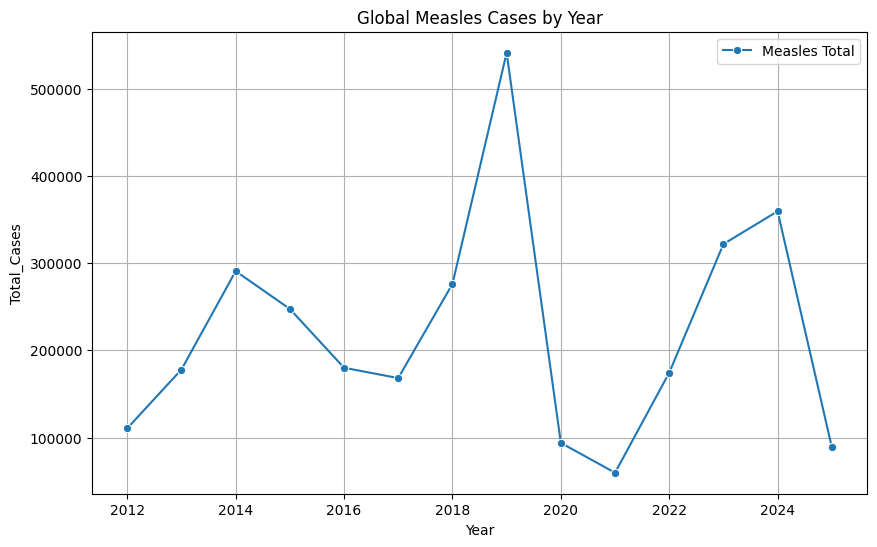

In [ ]:
# Group by year
yearly_summary = cases_year.groupby('year')[['measles_total']].sum().reset_index()

# Display the yearly totals
print("Yearly Totals for Measles:")
display(yearly_summary)

# Plotting the trend over years
plt.figure(figsize=(10, 6))
sns.lineplot(data=yearly_summary, x='year', y='measles_total', marker='o', label='Measles Total')

plt.title('Global Measles Cases by Year')
plt.xlabel('Year')
plt.ylabel('Total_Cases')
plt.legend()
plt.grid(True)
plt.show()

### global cases by month

,month,measles_total
0,1,399678.0
1,2,457913.0
2,3,494540.0
3,4,379619.0
4,5,297213.0
5,6,199601.0
6,7,152131.0
7,8,131964.0
8,9,122728.0
9,10,133755.0


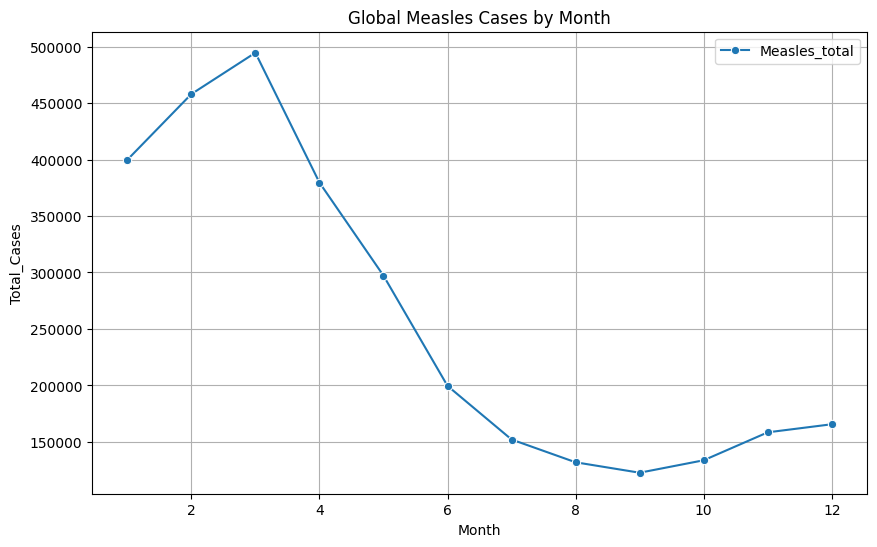

In [ ]:
#group by month
monthly_summary = cases_month.groupby('month')[['measles_total']].sum().reset_index()
display(monthly_summary)

plt.figure(figsize=(10, 6))
sns.lineplot(data=monthly_summary,x='month',y='measles_total',marker='o',label='Measles_total')

plt.title('Global Measles Cases by Month')
plt.xlabel('Month')
plt.ylabel('Total_Cases')
plt.legend()
plt.grid(True)
plt.show()


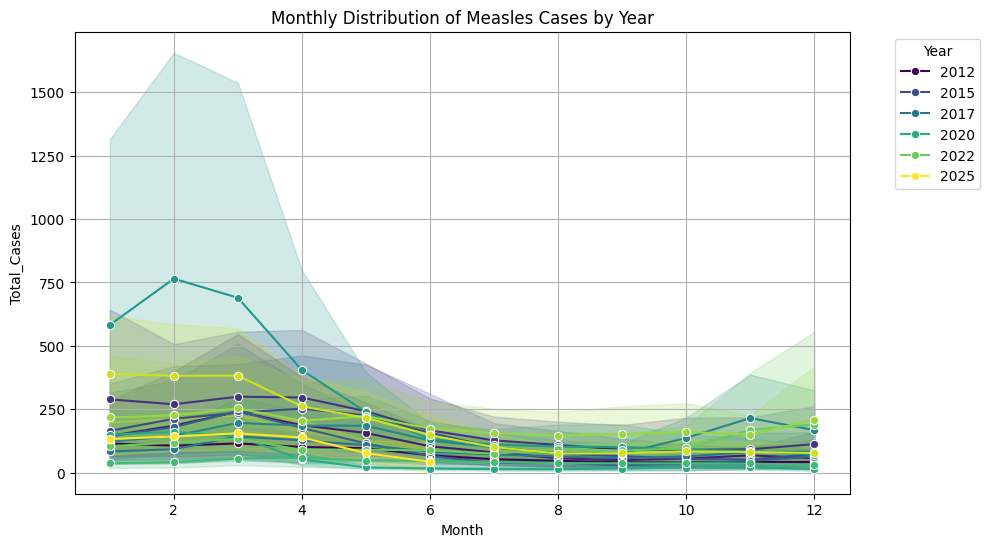

In [ ]:
#monthly distribution based on year
plt.figure(figsize=(10, 6))
sns.lineplot(data=cases_month, x='month', y='measles_total', hue='year', marker='o', palette='viridis')

plt.title('Monthly Distribution of Measles Cases by Year')
plt.xlabel('Month')
plt.ylabel('Total_Cases')
plt.legend(title='Year', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True)
plt.show()

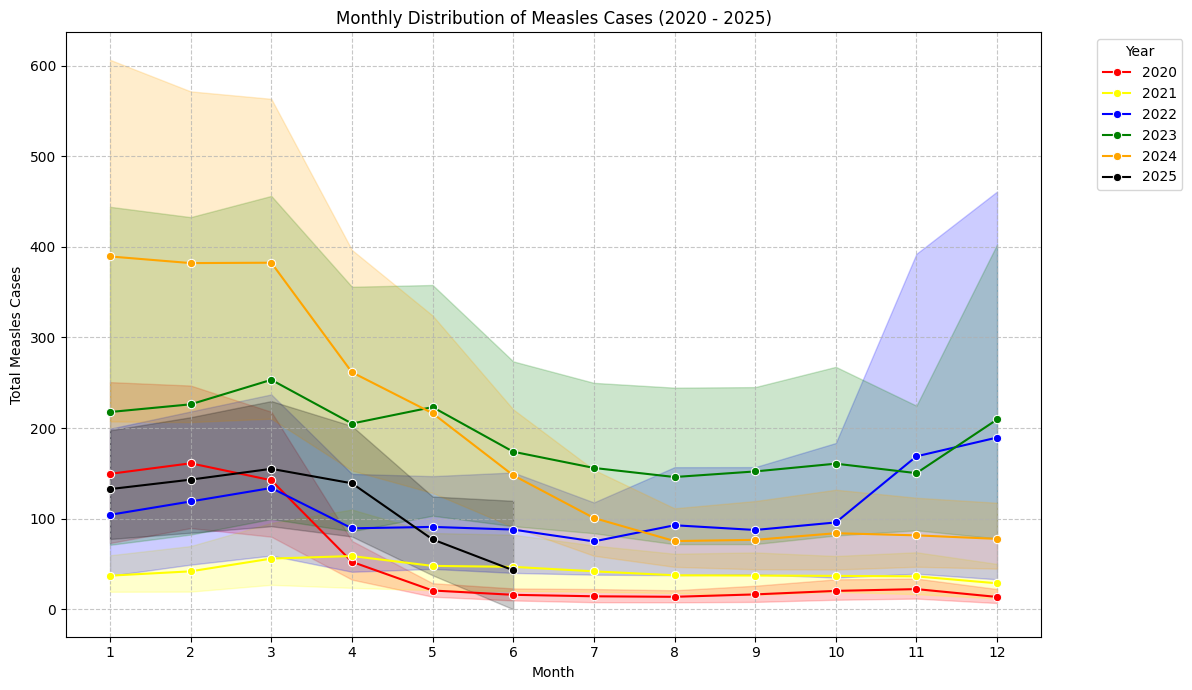

In [ ]:
# Filter data for years 2020-2025
cases_2020_2025 = cases_month[cases_month['year'].between(2020, 2025)]

#distinct colors
custom_palette = ["red", "yellow", "blue", "green", "orange", "black"]

plt.figure(figsize=(12, 7))
sns.lineplot(data=cases_2020_2025, x='month', y='measles_total', hue='year', marker='o', palette=custom_palette)

plt.title('Monthly Distribution of Measles Cases (2020 - 2025)')
plt.xlabel('Month')
plt.ylabel('Total Measles Cases')
plt.xticks(range(1, 13))
plt.legend(title='Year', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

Based on the graph, measles cases tend to be higher on the 1st 3 months and the cases start rising from october. Since 2022, the cases have incread rapidly and 2024 was the year with highest cases for the 1st 3 months and the cases started decreasing after April. Globally, after 2018 the cases rose,2019 was the highest among all and by 2020 the cases dropped sharply (clearly due to covid pandemic) then again,in 2022 the cases started rising and 2024 was the highest.

### Global Regional Distribution of Measles Cases

Measles Cases by Region in 2024:


,region,measles_total
0,EUR,127424.0
1,EMR,96624.0
2,AFR,86127.0
3,SEAR,36887.0
4,WPR,12011.0
5,AMR,461.0


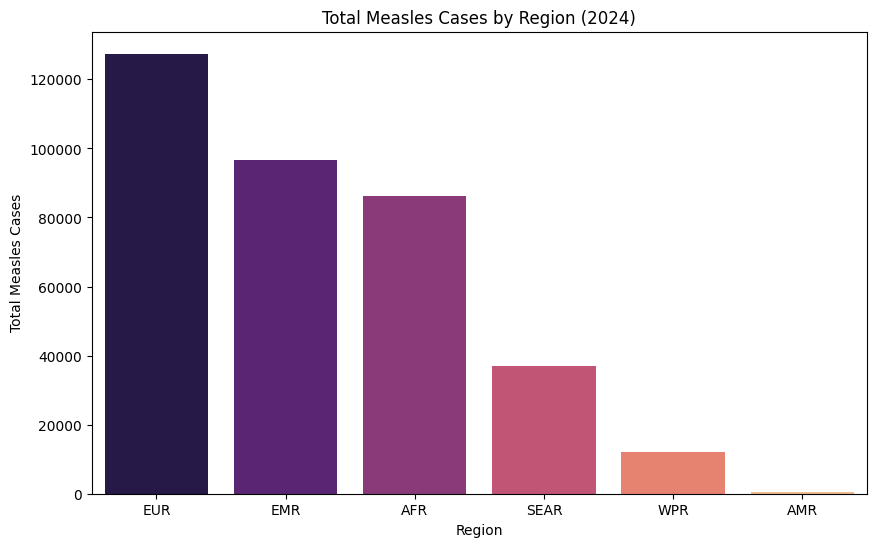

In [ ]:
# Identify regions with the highest measles cases in 2024
cases_2024 = cases_month[cases_month['year'] == 2024]
region_summary_2024 = cases_2024.groupby('region')['measles_total'].sum().sort_values(ascending=False).reset_index()

print("Measles Cases by Region in 2024:")
display(region_summary_2024)

# Visualize the regional distribution for 2024
plt.figure(figsize=(10, 6))
sns.barplot(data=region_summary_2024, x='region', y='measles_total', palette='magma')
plt.title('Total Measles Cases by Region (2024)')
plt.xlabel('Region')
plt.ylabel('Total Measles Cases')
plt.show()

Top 10 EUR Countries with Highest Measles Cases in 2024:


,country,measles_total
0,Romania,30691.0
1,Kazakhstan,28147.0
2,Russian Federation,22076.0
3,Azerbaijan,16690.0
4,Kyrgyzstan,14408.0
5,United Kingdom of Great Britain and Northern I...,2924.0
6,Bosnia and Herzegovina,1688.0
7,Türkiye,1523.0
8,Uzbekistan,1459.0
9,Italy,1055.0


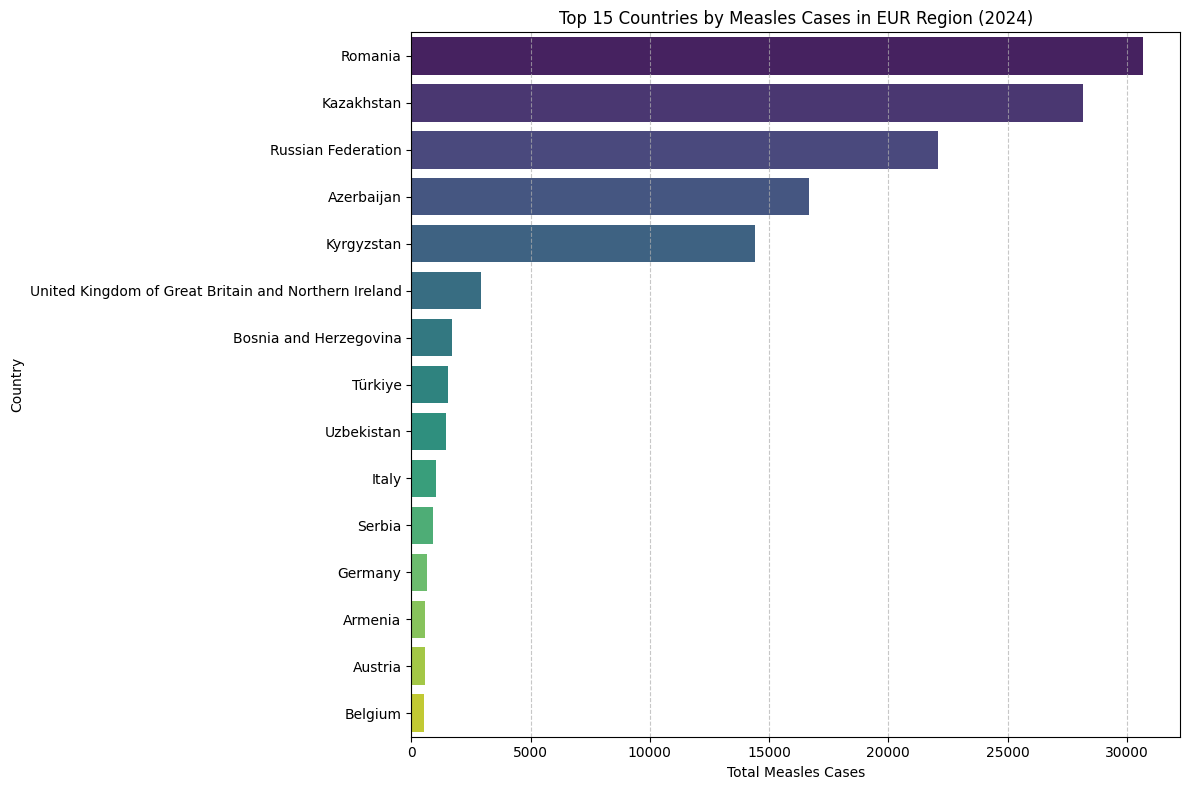

In [ ]:
# Filter 2024 data for the EUR region
eur_cases_2024 = cases_2024[cases_2024['region'] == 'EUR']

# Group by country to see the distribution within the region
eur_country_summary = eur_cases_2024.groupby('country')['measles_total'].sum().sort_values(ascending=False).reset_index()

print("Top 10 EUR Countries with Highest Measles Cases in 2024:")
display(eur_country_summary.head(10))

# Visualize the top 15 countries in the EUR region
plt.figure(figsize=(12, 8))
sns.barplot(data=eur_country_summary.head(15), x='measles_total', y='country', palette='viridis')
plt.title('Top 15 Countries by Measles Cases in EUR Region (2024)')
plt.xlabel('Total Measles Cases')
plt.ylabel('Country')
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

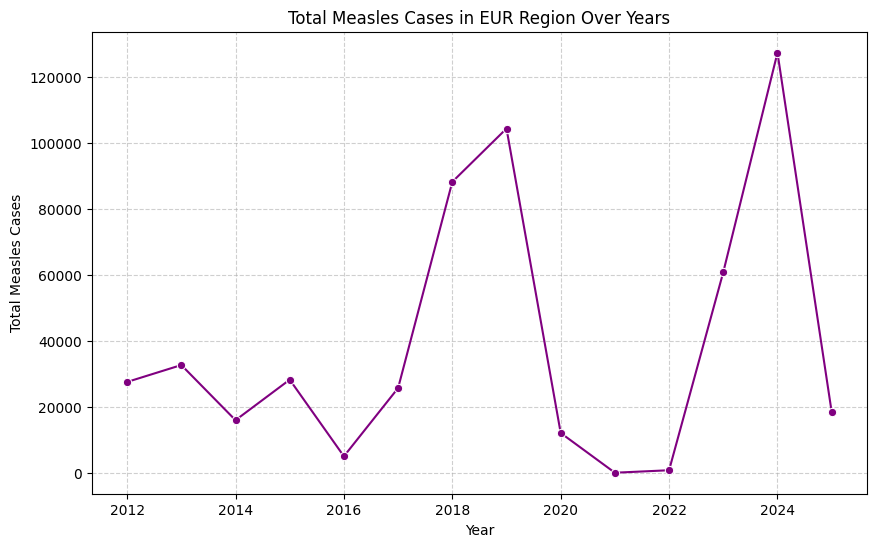

In [ ]:
# Analyze trends in the EUR region over the years
eur_yearly_trend = cases_year[cases_year['region'] == 'EURO'].groupby('year')['measles_total'].sum().reset_index()

plt.figure(figsize=(10, 6))
sns.lineplot(data=eur_yearly_trend, x='year', y='measles_total', marker='o', color='purple')

plt.title('Total Measles Cases in EUR Region Over Years')
plt.xlabel('Year')
plt.ylabel('Total Measles Cases')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

Total Measles Cases by Region (Historical Data):


,region,measles_total
0,AFRO,901018
1,SEARO,632557
2,EURO,548694
3,EMRO,514845
4,WPRO,434938
5,AMRO,58733


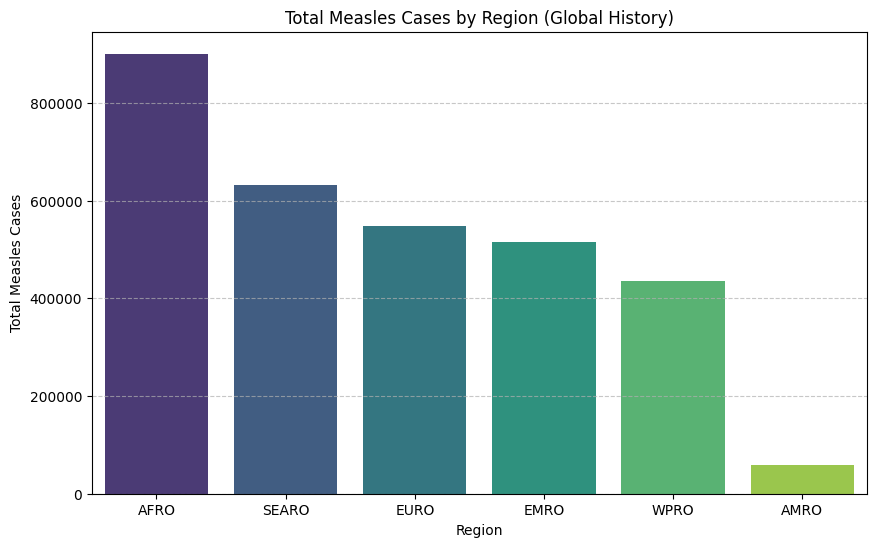

In [ ]:
# Aggregate measles cases by region
regional_distribution = cases_year.groupby('region')['measles_total'].sum().sort_values(ascending=False).reset_index()

print("Total Measles Cases by Region (Historical Data):")
display(regional_distribution)

# Visualize the distribution
plt.figure(figsize=(10, 6))
sns.barplot(data=regional_distribution, x='region', y='measles_total', palette='viridis')
plt.title('Total Measles Cases by Region (Global History)')
plt.xlabel('Region')
plt.ylabel('Total Measles Cases')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

### Highest avg measles cases by region

Average Measles Cases by Region (Historical Data):


,region,measles_total
0,SEARO,4245.348993
1,EMRO,1812.834507
2,AFRO,1499.198003
3,WPRO,1275.478006
4,EURO,809.283186
5,AMRO,179.611621


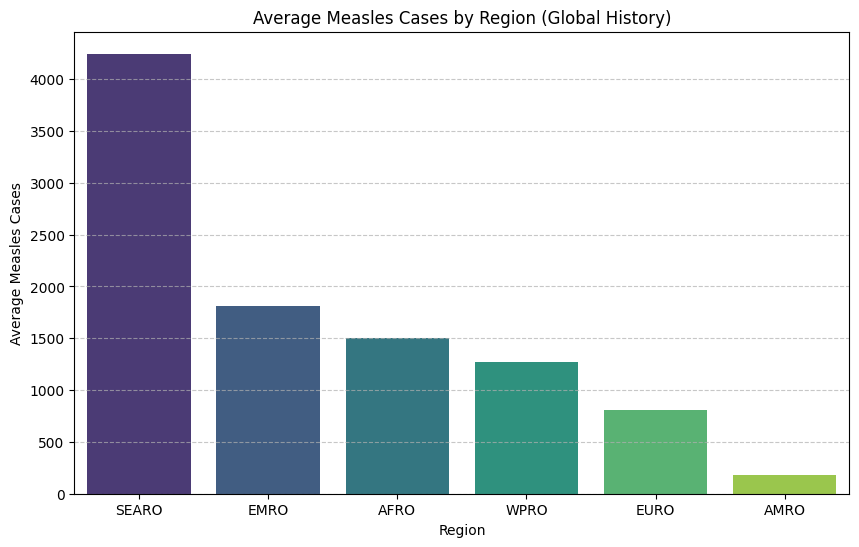

In [ ]:
# highest average measles cases by region
regional_distribution = cases_year.groupby('region')['measles_total'].mean().sort_values(ascending=False).reset_index()

print("Average Measles Cases by Region (Historical Data):")
display(regional_distribution)

# Visualize the distribution
plt.figure(figsize=(10, 6))
sns.barplot(data=regional_distribution, x='region', y='measles_total', palette='viridis')
plt.title('Average Measles Cases by Region (Global History)')
plt.xlabel('Region')
plt.ylabel('Average Measles Cases')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

### Identifying the Highest Measles Burden: Regions and Countries

Historical Regional Measles Burden:


,Total Cases,Average Cases per Year/Country,Data Points
region,,,
AFRO,901018,1499.198003,601
SEARO,632557,4245.348993,149
EURO,548694,809.283186,678
EMRO,514845,1812.834507,284
WPRO,434938,1275.478006,341
AMRO,58733,179.611621,327



Top 10 Countries with Highest Cumulative Measles Burden:


,country,region,measles_total
0,India,SEARO,474525
1,Madagascar,AFRO,225947
2,Nigeria,AFRO,210073
3,China,WPRO,172872
4,Philippines,WPRO,148930
5,Yemen,EMRO,147829
6,Ukraine,EURO,136311
7,Pakistan,EMRO,132292
8,Ethiopia,AFRO,117825
9,Democratic Republic of the Congo,AFRO,84184


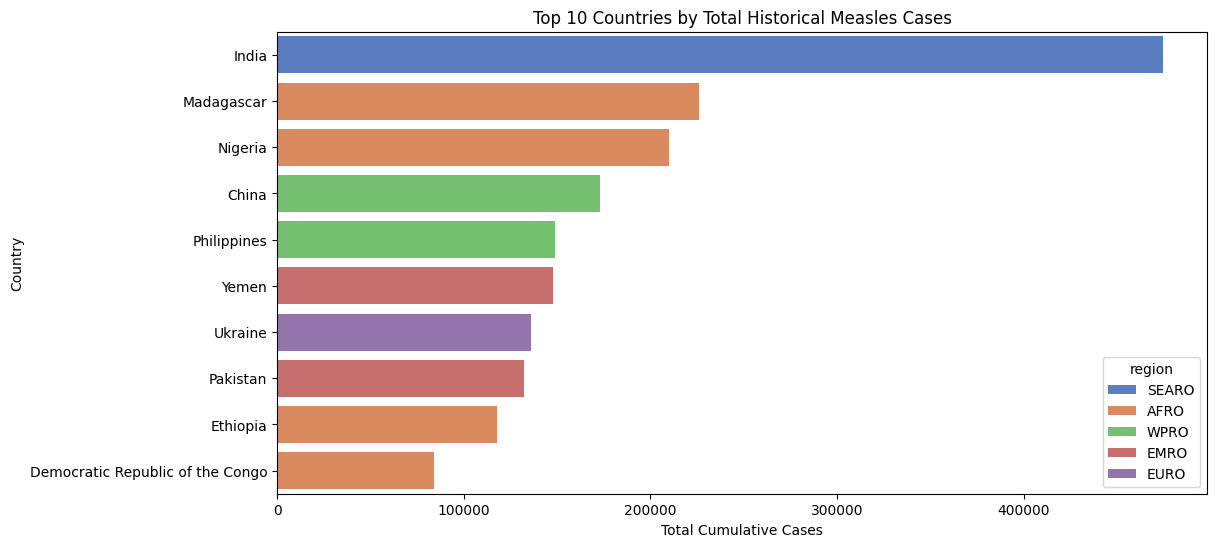

In [ ]:
# Calculate historical regional burden (Total and Mean per year)
regional_burden = cases_year.groupby('region')['measles_total'].agg(['sum', 'mean', 'count']).sort_values(by='sum', ascending=False)
regional_burden.columns = ['Total Cases', 'Average Cases per Year/Country', 'Data Points']

print("Historical Regional Measles Burden:")
display(regional_burden)

# Identify top 10 countries with the highest historical burden
country_burden = cases_year.groupby(['country', 'region'])['measles_total'].sum().sort_values(ascending=False).reset_index().head(10)

print("\nTop 10 Countries with Highest Cumulative Measles Burden:")
display(country_burden)

# Visualization of Top 10 Countries
plt.figure(figsize=(12, 6))
sns.barplot(data=country_burden, x='measles_total', y='country', hue='region', palette='muted')
plt.title('Top 10 Countries by Total Historical Measles Cases')
plt.xlabel('Total Cumulative Cases')
plt.ylabel('Country')
plt.show()

### Seasonal Patterns by Region
This analysis explores how measles cases fluctuate throughout the year across different global regions.

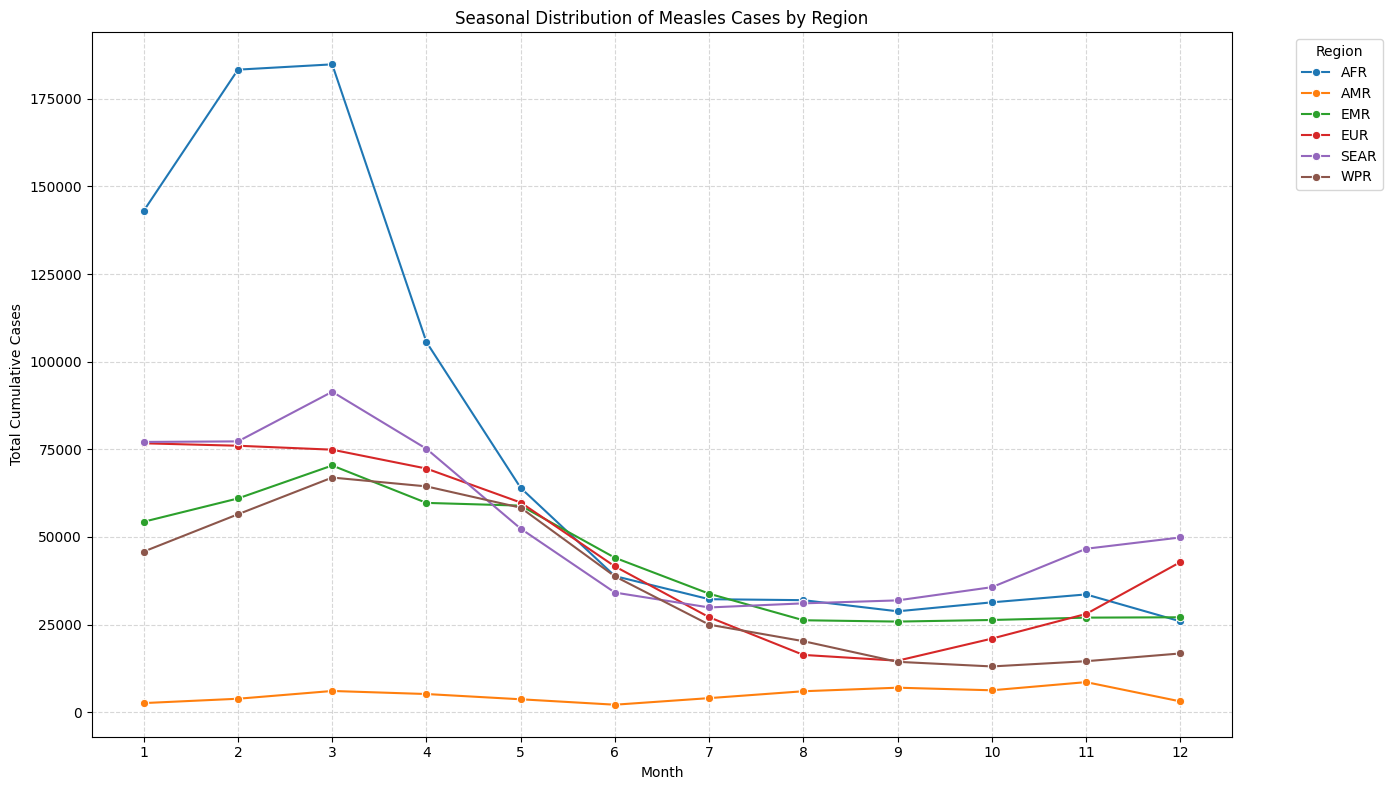

In [ ]:
# Group by region and month to find average seasonal trends
regional_seasonal = cases_month.groupby(['region', 'month'])['measles_total'].sum().reset_index()

plt.figure(figsize=(14, 8))
sns.lineplot(data=regional_seasonal, x='month', y='measles_total', hue='region', marker='o', palette='tab10')

plt.title('Seasonal Distribution of Measles Cases by Region')
plt.xlabel('Month')
plt.ylabel('Total Cumulative Cases')
plt.xticks(range(1, 13))
plt.legend(title='Region', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# Outbreaks

#### Creating outbreak label

mean+std: Outbreaks were defined as years where incidence exceeded `one standard deviation above the mean.`

iqr: `incidence> median+2*IQR`

90th percentile: incidence>`p90`

In [ ]:
col = "measles_incidence_rate_per_1000000_total_population"
cases_year["threshold_country_mean_std"] = (
    cases_year.groupby("country")[
        col
    ].transform(lambda x: x.mean() + x.std())
)

cases_year["outbreak_mean_std"] = (
    cases_year[col]> cases_year["threshold_country_mean_std"]
)

#outbreak_iqr
iqr_stats = cases_year.groupby("country")[col].agg(
    median="median",
    q1=lambda x: x.quantile(0.25),
    q3=lambda x: x.quantile(0.75)
)
iqr_stats["iqr"] = iqr_stats["q3"] - iqr_stats["q1"]
iqr_stats["iqr_thr"] = iqr_stats["median"] + 2 * iqr_stats["iqr"]
cases_year = cases_year.merge(iqr_stats[["iqr_thr"]], on="country", how="left")
cases_year["outbreak_iqr"] = cases_year[col] > cases_year["iqr_thr"]

# outbreak_p90
p_stats = cases_year.groupby("country")[col].quantile(0.9).rename("p90")
cases_year = cases_year.merge(p_stats, on="country", how="left")
cases_year["outbreak_p90"] = cases_year[col] > cases_year["p90"]
display(cases_year.head(30))

,region,country,iso3,year,total_population,annualized_population_most_recent_year_only,total_suspected_measles_rubella_cases,measles_total,measles_lab_confirmed,measles_epi_linked,...,rubella_clinical,rubella_incidence_rate_per_1000000_total_population,discarded_cases,discarded_non_measles_rubella_cases_per_100000_total_population,threshold_country_mean_std,outbreak_mean_std,iqr_thr,outbreak_iqr,p90,outbreak_p90
0,AFRO,Algeria,DZA,2012,37646166,37646166,76.0,55,2,0,...,0,0.35,8.0,0.02,21.976039,False,9.185,False,8.367,False
1,AFRO,Algeria,DZA,2013,38414172,38414172,85.0,0,0,0,...,0,0.75,56.0,0.15,21.976039,False,9.185,False,8.367,False
2,AFRO,Algeria,DZA,2014,39205031,39205031,49.0,0,0,0,...,0,0.08,46.0,0.12,21.976039,False,9.185,False,8.367,False
3,AFRO,Algeria,DZA,2015,40019529,40019529,109.0,62,2,60,...,0,0.05,45.0,0.11,21.976039,False,9.185,False,8.367,False
4,AFRO,Algeria,DZA,2016,40850721,40850721,93.0,49,21,27,...,0,0.27,33.0,0.08,21.976039,False,9.185,False,8.367,False
5,AFRO,Algeria,DZA,2017,41689299,41689299,314.0,231,74,23,...,0,0.53,61.0,0.15,21.976039,False,9.185,False,8.367,False
6,AFRO,Algeria,DZA,2018,42505035,42505035,345.0,287,22,0,...,0,0.75,26.0,0.06,21.976039,False,9.185,False,8.367,False
7,AFRO,Algeria,DZA,2019,43294546,43294546,2688.0,2585,1469,0,...,0,0.72,72.0,0.17,21.976039,True,9.185,True,8.367,True
8,AFRO,Algeria,DZA,2020,44042091,44042091,101.0,35,31,2,...,0,0.05,64.0,0.15,21.976039,False,9.185,False,8.367,False
9,AFRO,Algeria,DZA,2021,44761099,44761099,58.0,37,36,0,...,0,0.04,19.0,0.04,21.976039,False,9.185,False,8.367,False


,Mean_Std vs IQR,Mean_Std vs P90,IQR vs P90
Matching %,0.942017,0.963025,0.947899


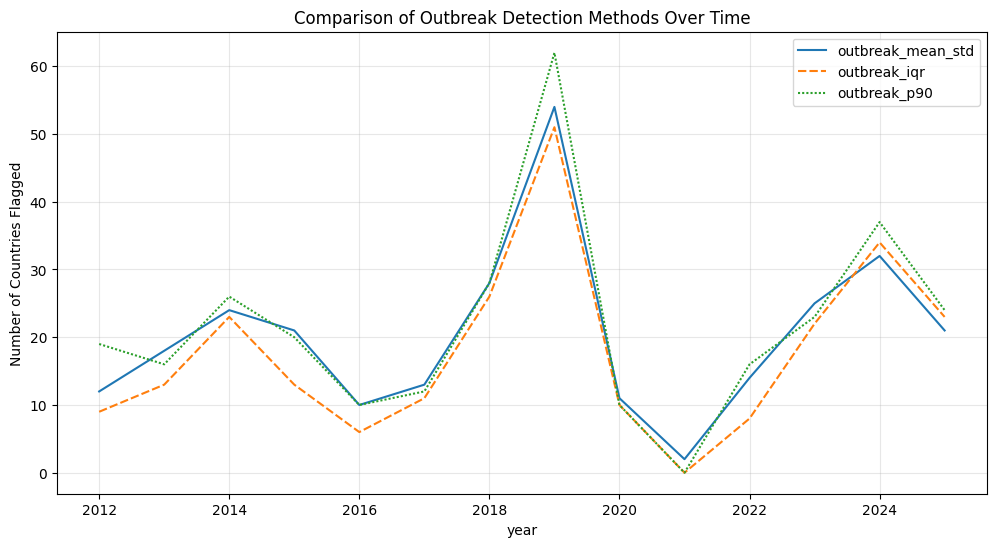

In [ ]:
def agreement(a, b):
    return (cases_year[a] == cases_year[b]).mean()

agreement_table = pd.DataFrame({
    "Mean_Std vs IQR": [agreement("outbreak_mean_std", "outbreak_iqr")],
    "Mean_Std vs P90": [agreement("outbreak_mean_std", "outbreak_p90")],
    "IQR vs P90": [agreement("outbreak_iqr", "outbreak_p90")]
}, index=["Matching %"])

display(agreement_table)

# Compare the total count of outbreaks detected by each method
year_compare = cases_year.groupby("year")[[
    "outbreak_mean_std",
    "outbreak_iqr",
    "outbreak_p90"
]].sum()

plt.figure(figsize=(12, 6))
sns.lineplot(data=year_compare)
plt.title("Comparison of Outbreak Detection Methods Over Time")
plt.ylabel("Number of Countries Flagged")
plt.grid(True, alpha=0.3)
plt.show()

### Measles Incidence Stability Analysis
Calculating the Coefficient of Variation (CV) per country to identify where data is most volatile.

In [ ]:
# Calculate Coefficient of Variation (CV = Std Dev / Mean)
stability_df = cases_year.groupby('country')[col].agg(['mean', 'std']).reset_index()
stability_df['cv'] = stability_df['std'] / stability_df['mean']

# Sort by highest CV to see most unstable countries
stability_df = stability_df.sort_values(by='cv', ascending=False).reset_index(drop=True)

print("Top 20 Countries with Highest Volatility (CV):")
display(stability_df.head(20))

# Global summary
avg_cv = stability_df['cv'].mean()
print(f"\nGlobal Average Coefficient of Variation: {avg_cv:.2f}")

Top 20 Countries with Highest Volatility (CV):


,country,mean,std,cv
0,Democratic People's Republic of Korea,0.022857,0.085524,3.741657
1,Micronesia (Federated States of),268.855714,1005.965969,3.741657
2,Zimbabwe,23.662857,85.479285,3.612382
3,Solomon Islands,121.449231,437.891429,3.605551
4,Tunisia,29.519286,104.795465,3.550068
5,Madagascar,572.829286,2013.909136,3.515723
6,Papua New Guinea,24.279231,84.127775,3.465010
7,Cuba,0.007500,0.025981,3.464102
8,Guatemala,0.005455,0.018091,3.316625
9,Belize,3.610909,11.976031,3.316625



Global Average Coefficient of Variation: 1.73


In [ ]:
year_compare = df.groupby("year")[[
    "outbreak_mean_std",
    "outbreak_iqr",
    "outbreak_p90"
]].sum()

print(year_compare.tail(10))

In [ ]:
cases_year["outbreak_mean_std"] = cases_year["outbreak_mean_std"].astype(int)
heatmap_data = (
    cases_year.pivot_table(
        index="country",
        columns="year",
        values="outbreak_mean_std",
        aggfunc="max"
    )
    .fillna(0)
    .astype(int)   # ✅ critical line
)

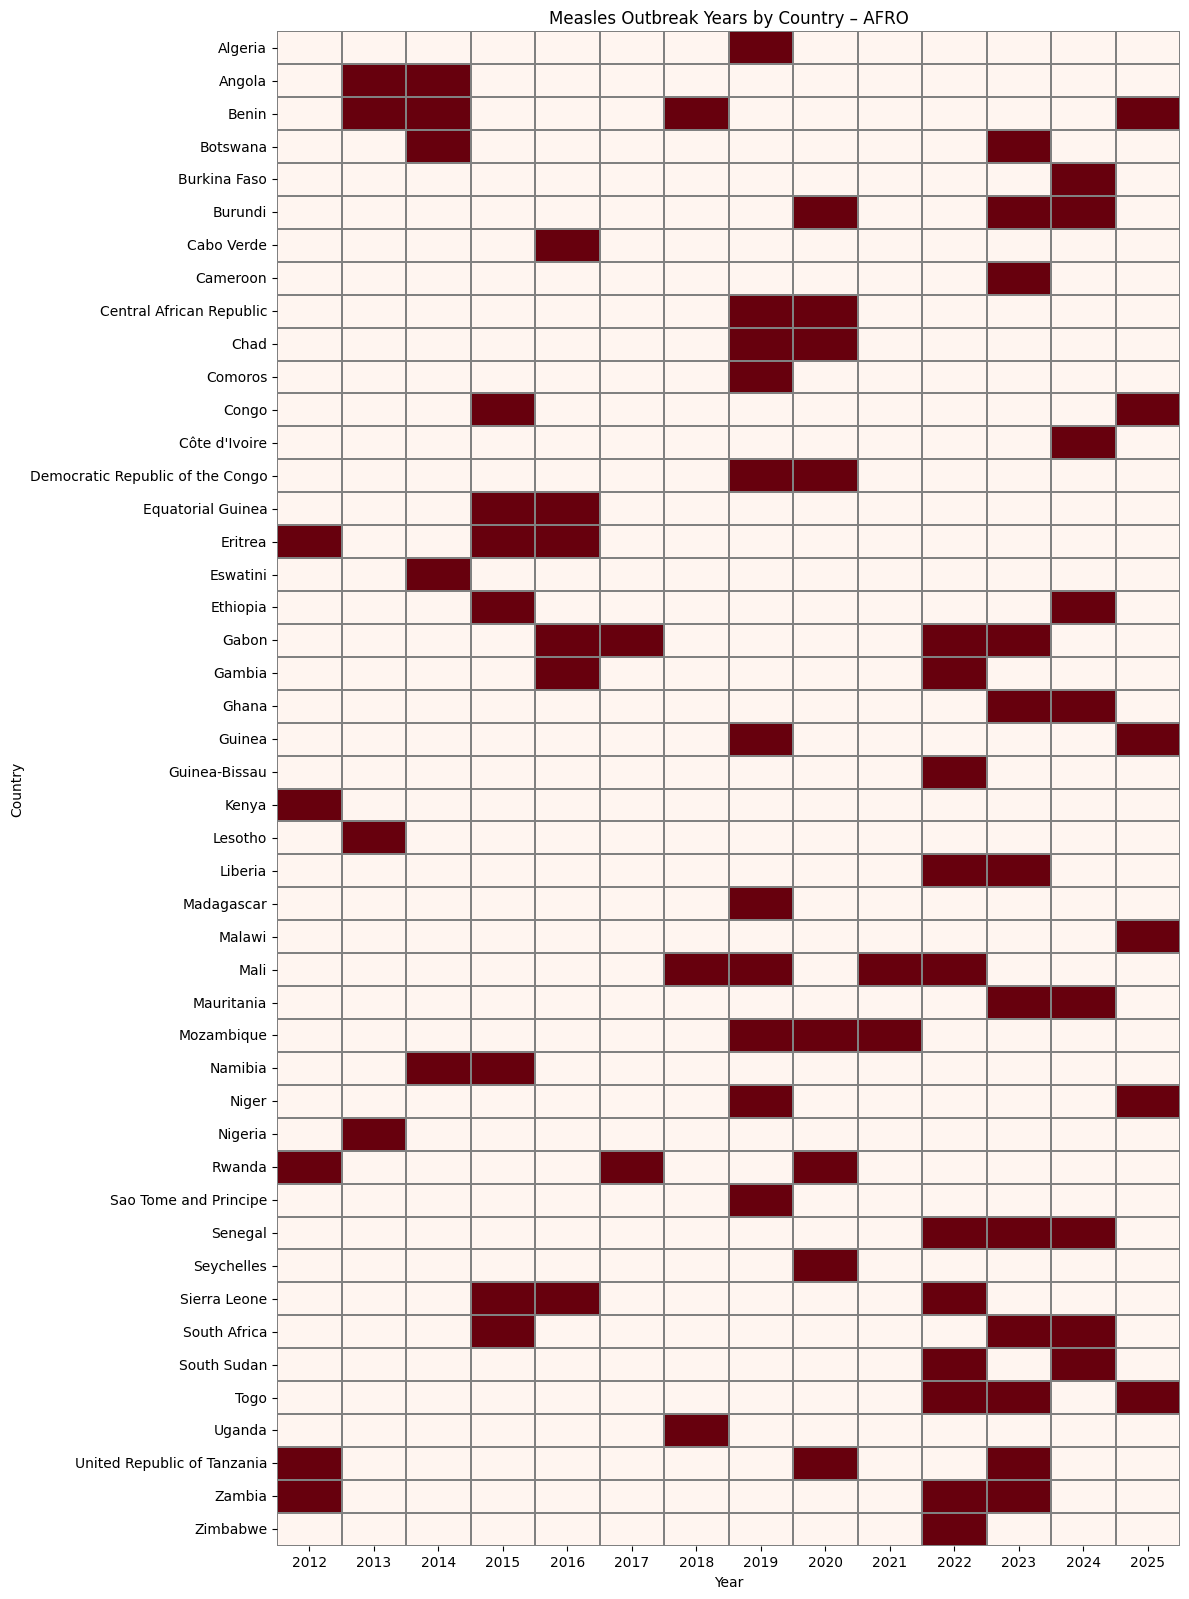

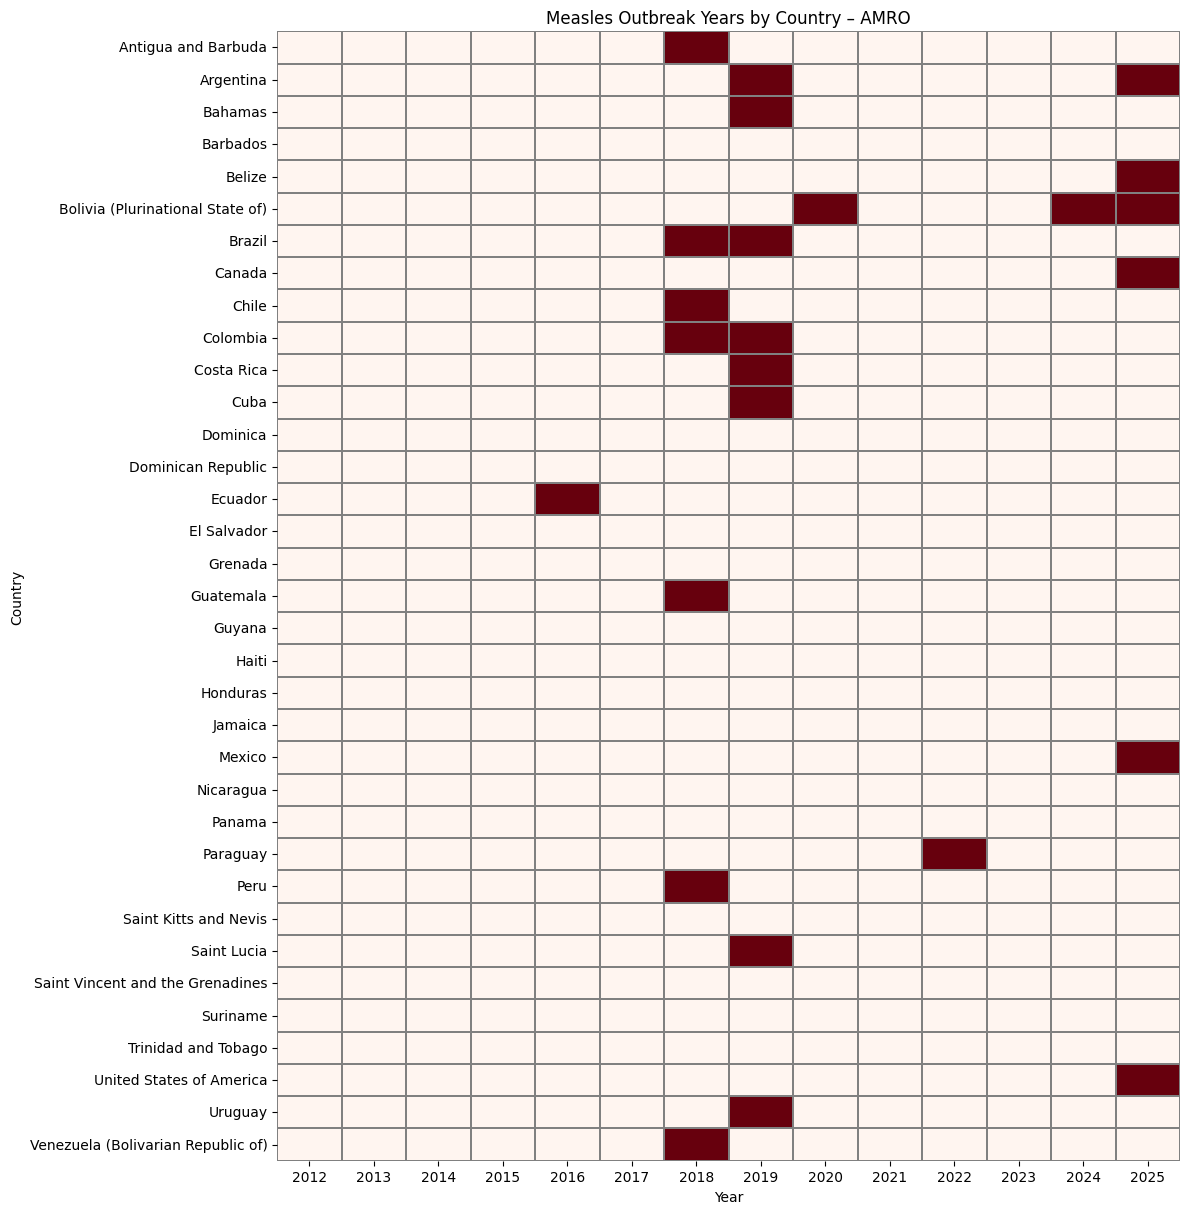

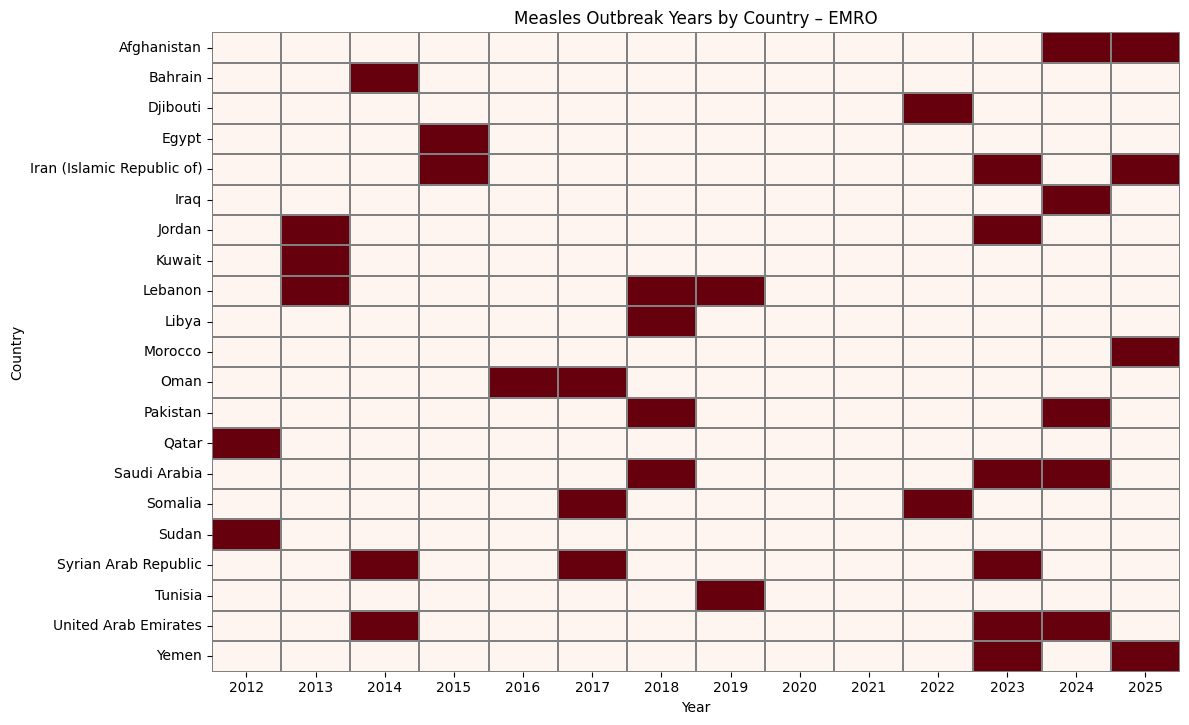

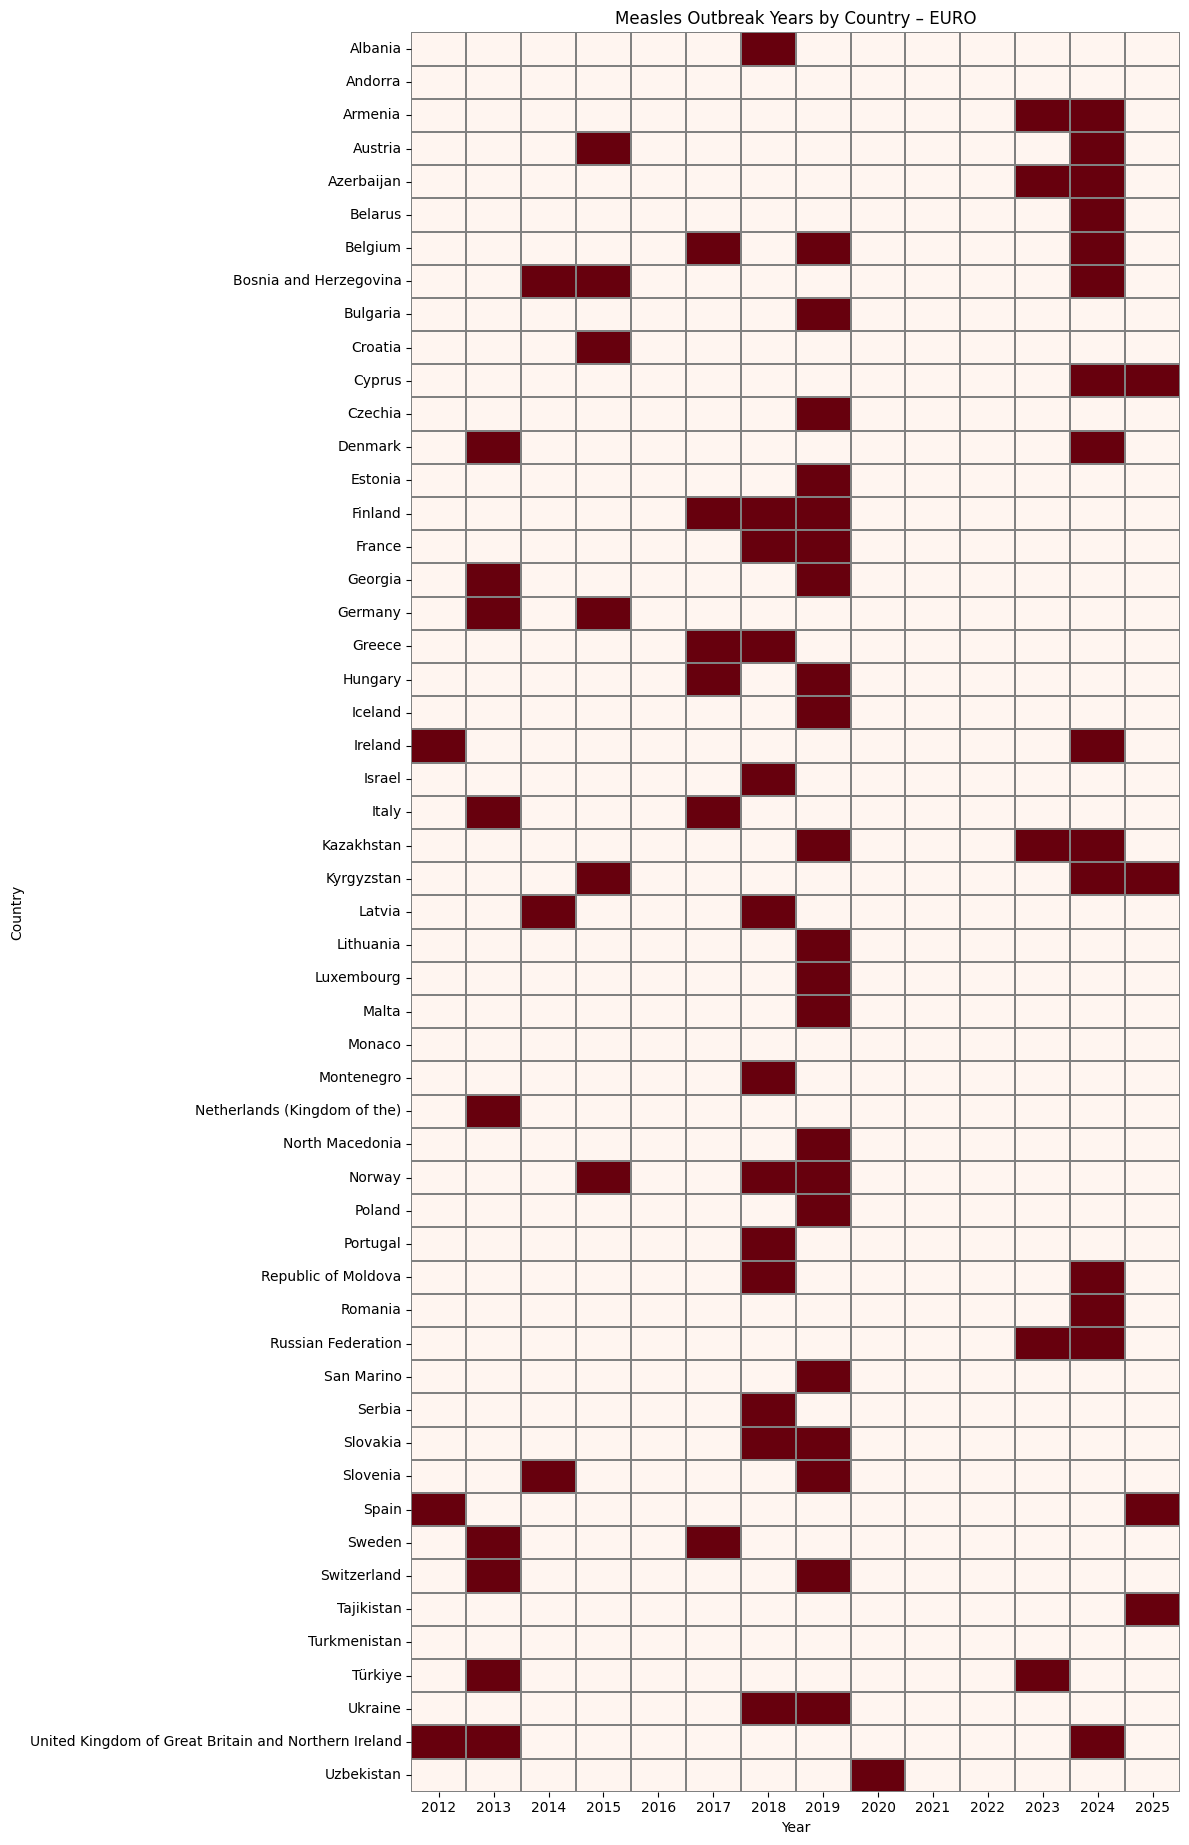

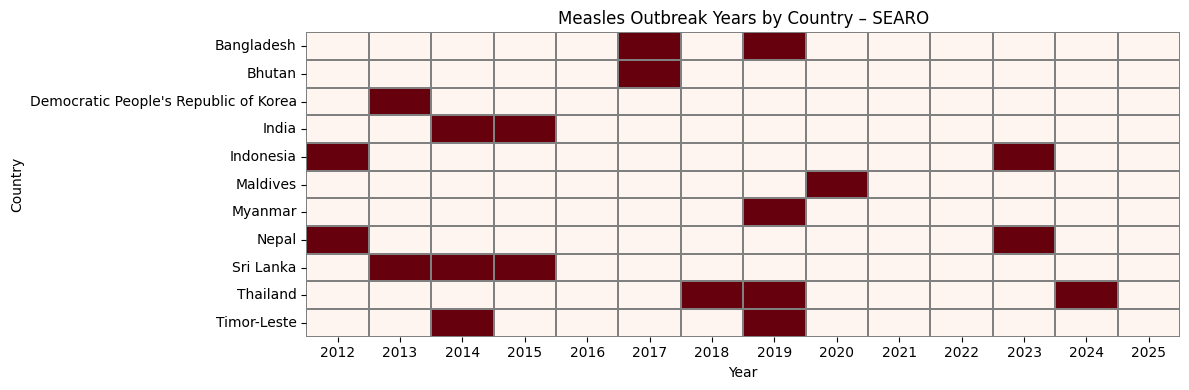

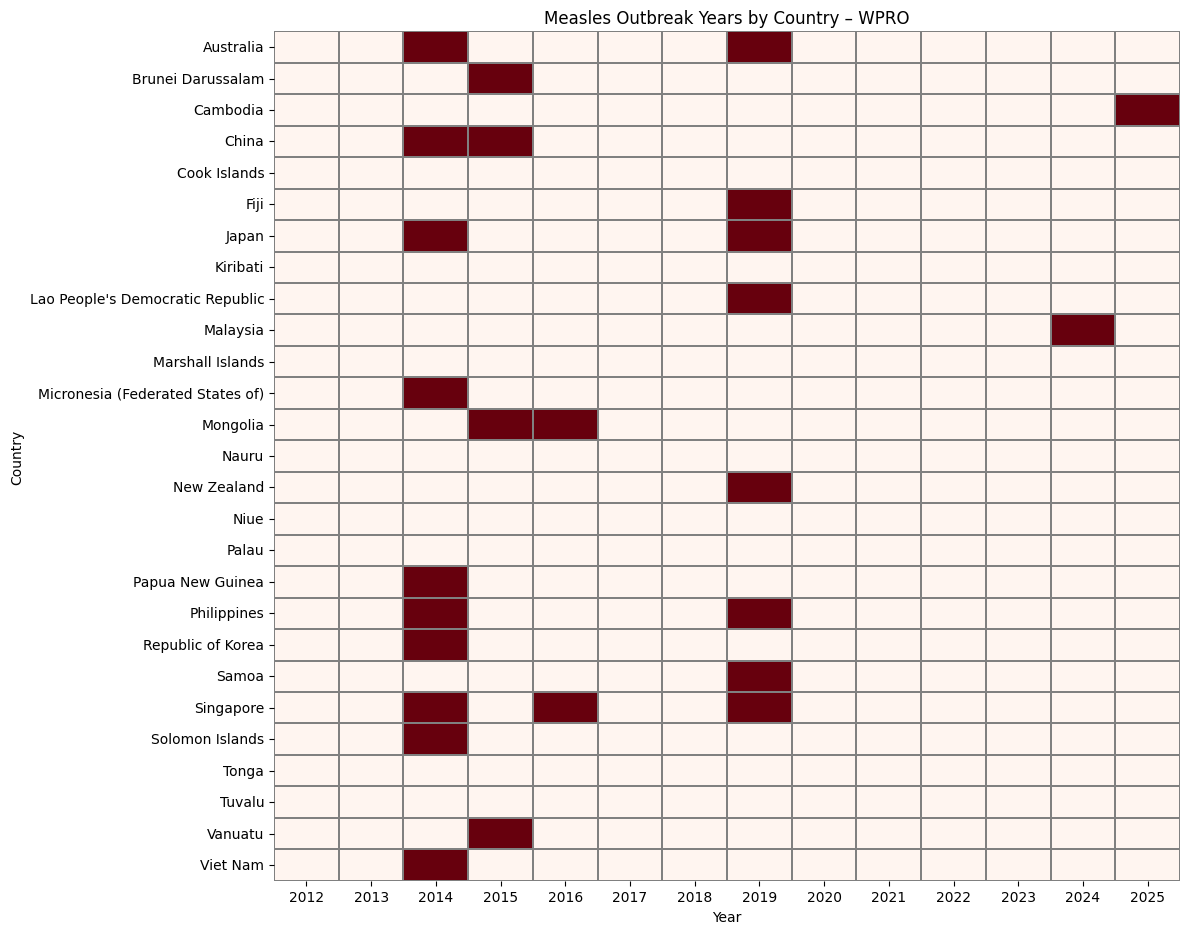

In [ ]:
regions = cases_year["region"].unique()

for region in regions:
    region_countries = (
        cases_year[cases_year["region"] == region]["country"]
        .unique()
    )

    region_matrix = heatmap_data.loc[
        heatmap_data.index.intersection(region_countries)
    ]

    # Skip empty regions
    if region_matrix.empty:
        continue

    plt.figure(figsize=(12, max(4, len(region_matrix) * 0.35)))

    sns.heatmap(
        region_matrix,
        cmap="Reds",
        cbar=False,
        linewidths=0.3,
        linecolor="gray"
    )

    plt.title(f"Measles Outbreak Years by Country – {region}")
    plt.xlabel("Year")
    plt.ylabel("Country")

    plt.tight_layout()
    plt.show()


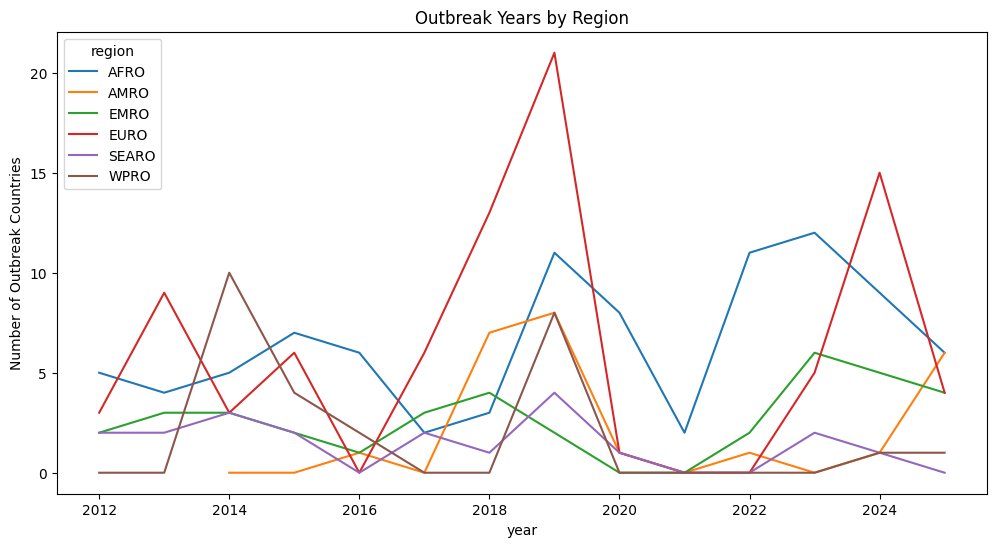

In [ ]:
region_year = (
    cases_year.groupby(["region", "year"])["outbreak_mean_std"]
    .sum()
    .reset_index()
)

plt.figure(figsize=(12,6))
sns.lineplot(data=region_year, x="year", y="outbreak_mean_std", hue="region")
plt.title("Outbreak Years by Region")
plt.ylabel("Number of Outbreak Countries")
plt.show()

#### Which countries contributed the most

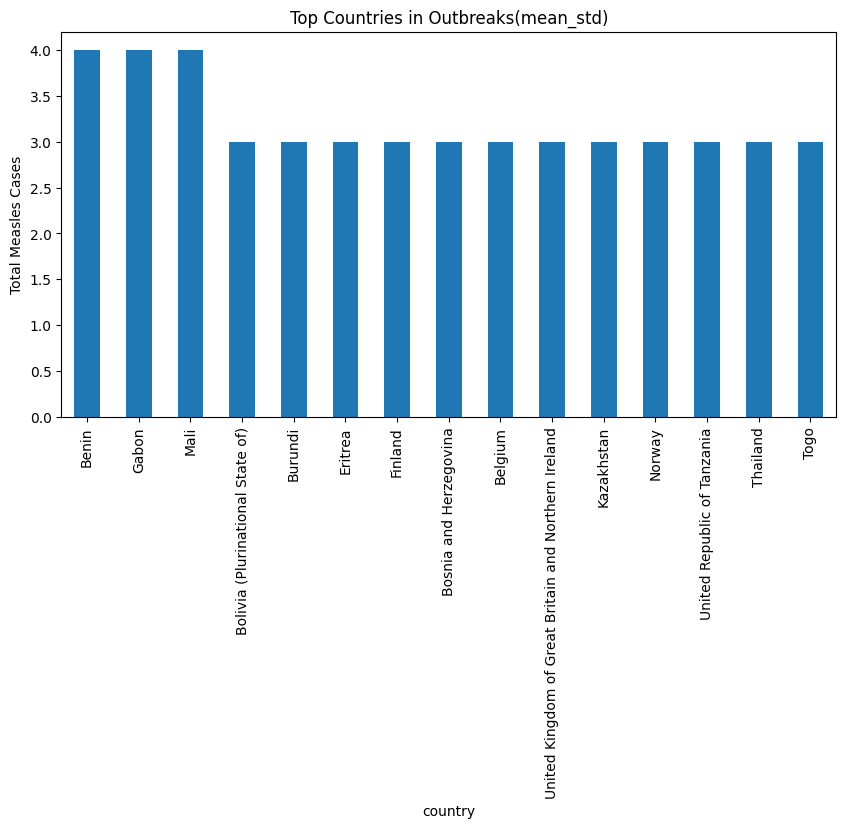

In [ ]:
top_countries = (
    cases_year.groupby("country")["outbreak_mean_std"]
    .sum()
    .sort_values(ascending=False)
    .head(15)
)

top_countries.plot(kind="bar", figsize=(10,5), title="Top Countries in Outbreaks(mean_std)")
plt.ylabel("Total Measles Cases")
plt.xticks(rotation=90)
plt.show()

#### Trend of outbreaks in countries

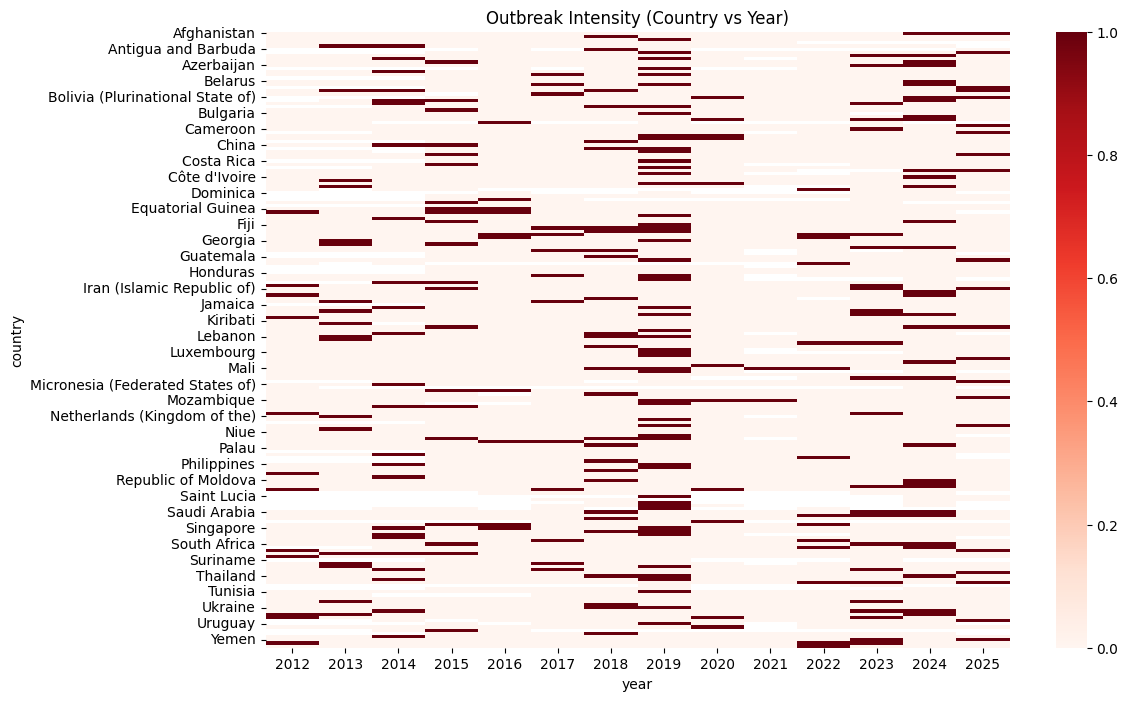

In [ ]:
pivot = cases_year.pivot_table(
    index="country",
    columns="year",
    values="outbreak_mean_std",
    aggfunc="sum"
)

plt.figure(figsize=(12,8))
sns.heatmap(pivot, cmap="Reds")
plt.title("Outbreak Intensity (Country vs Year)")
plt.show()

# Research Question

`Is the country going to face an outbreak in future?`

-Transforming time series data into a supervised learning problem using lag features and applying Random Forest classification.

#### Train the model on outbreak data till 2022

In [ ]:
df = cases_year.copy()
df[col] = pd.to_numeric(df[col], errors="coerce")

df = df.sort_values(["country", "year"]).reset_index(drop=True)
df = pd.get_dummies(df, columns=["region"], prefix="region")

In [ ]:
#train_countries = df[df["year"] <= 2022]

# **Feature engineering**


In [ ]:
#Lag features (t-1)
df["incidence_lag1"] = df.groupby("country")[
    "measles_incidence_rate_per_1000000_total_population"
].shift(1)

df["cases_lag1"] = df.groupby("country")["measles_total"].shift(1)

df["growth_lag1"] = df.groupby("country")[
    "measles_incidence_rate_per_1000000_total_population"
].pct_change()

df["growth_lag1"] = df["growth_lag1"].replace([np.inf, -np.inf], np.nan)

# #Rolling mean (past 3 years, excluding current)
df["roll3_lag1"] = df.groupby("country")[
    "measles_incidence_rate_per_1000000_total_population"
].transform(lambda x: x.shift(1).rolling(3).mean())

df_model = df.dropna().reset_index(drop=True)

Training the model for data till 2022. we will test the model on data after 2022


In [ ]:
df_model.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1092 entries, 0 to 1091
Data columns (total 34 columns):
 #   Column                                                           Non-Null Count  Dtype  
---  ------                                                           --------------  -----  
 0   country                                                          1092 non-null   object 
 1   iso3                                                             1092 non-null   object 
 2   year                                                             1092 non-null   int64  
 3   total_population                                                 1092 non-null   int64  
 4   annualized_population_most_recent_year_only                      1092 non-null   int64  
 5   total_suspected_measles_rubella_cases                            1092 non-null   float64
 6   measles_total                                                    1092 non-null   int64  
 7   measles_lab_confirmed                     

# Model evaluation and selection

In [ ]:
features_base = [
    "incidence_lag1",
    "cases_lag1",
    "growth_lag1",
    "roll3_lag1",
] + [c for c in df.columns if c.startswith("region_")]

### Cross validation

In [ ]:
from sklearn.model_selection import GridSearchCV, KFold, cross_val_score

# Prepare the full dataset for nested CV
X_full, y_full = df_model[features_base], df_model["outbreak_mean_std"]

# --- Random Forest Hyperparameters ---
param_grid_rf = {
    'n_estimators': [100, 200],
    'max_depth': [5, 10],
    'min_samples_leaf': [1, 2],
    'class_weight': ['balanced']
}
print(f"RF CV Hyperparameter Grid: {param_grid_rf}")

inner_cv = KFold(n_splits=3, shuffle=True, random_state=42)
outer_cv = KFold(n_splits=5, shuffle=True, random_state=42)

rfc = RandomForestClassifier(random_state=42)
model_to_tune = GridSearchCV(
    estimator=rfc,
    param_grid=param_grid_rf,
    cv=inner_cv,
    scoring='roc_auc',
    n_jobs=-1
)

nested_scores_rf = cross_val_score(
    estimator=model_to_tune,
    X=X_full,
    y=y_full,
    cv=outer_cv,
    scoring='roc_auc',
    n_jobs=-1
)

print(f"Mean RF ROC-AUC: {nested_scores_rf.mean():.4f}")

# --- Logistic Regression Hyperparameters ---
params_lr = {'max_iter': 1000, 'class_weight': 'balanced', 'random_state': 42}
print(f"\nLR CV Parameters: {params_lr}")

lr_model = LogisticRegression(**params_lr)
nested_scores_lr = cross_val_score(
    estimator=lr_model,
    X=X_full,
    y=y_full,
    cv=outer_cv,
    scoring='roc_auc',
    n_jobs=-1
)

print(f"Mean LR ROC-AUC: {nested_scores_lr.mean():.4f}")

# --- SVM Hyperparameters ---
params_svc = {'probability': True, 'class_weight': 'balanced', 'random_state': 42}
print(f"\nSVM CV Parameters: {params_svc}")

svc_model = SVC(**params_svc)
nested_scores_svc = cross_val_score(
    estimator=svc_model,
    X=X_full,
    y=y_full,
    cv=outer_cv,
    scoring='roc_auc',
    n_jobs=-1
)

print(f"Mean SVM ROC-AUC: {nested_scores_svc.mean():.4f}")

RF CV Hyperparameter Grid: {'n_estimators': [100, 200], 'max_depth': [5, 10], 'min_samples_leaf': [1, 2], 'class_weight': ['balanced']}
Mean RF ROC-AUC: 0.8903

LR CV Parameters: {'max_iter': 1000, 'class_weight': 'balanced', 'random_state': 42}
Mean LR ROC-AUC: 0.6923

SVM CV Parameters: {'probability': True, 'class_weight': 'balanced', 'random_state': 42}
Mean SVM ROC-AUC: 0.6454


In [ ]:
models = {
    "Logistic": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "RandomForest": RandomForestClassifier(
        n_estimators=200, max_depth=6, class_weight="balanced", random_state=42
    ),
    "SVM": SVC(probability=True, class_weight="balanced")
}

# Prepare the data for training and testing
train = df_model[df_model["year"] <= 2022]
test  = df_model[df_model["year"] > 2022]

X_train, y_train = train[features_base], train["outbreak_mean_std"]
X_test, y_test = test[features_base], test["outbreak_mean_std"]

for name, model in models.items():
    model.fit(X_train, y_train)

In [ ]:
for name, model in models.items():
    preds = model.predict(X_test)
    probs = model.predict_proba(X_test)[:, 1]

    print(f"\n{name}")
    print(classification_report(y_test, preds))
    print("ROC-AUC:", roc_auc_score(y_test, probs))


Logistic
              precision    recall  f1-score   support

       False       0.84      0.61      0.71       248
        True       0.26      0.55      0.35        62

    accuracy                           0.60       310
   macro avg       0.55      0.58      0.53       310
weighted avg       0.73      0.60      0.64       310

ROC-AUC: 0.6027575442247659

RandomForest
              precision    recall  f1-score   support

       False       0.91      0.86      0.89       248
        True       0.55      0.68      0.60        62

    accuracy                           0.82       310
   macro avg       0.73      0.77      0.74       310
weighted avg       0.84      0.82      0.83       310

ROC-AUC: 0.8680411030176899

SVM
              precision    recall  f1-score   support

       False       0.82      0.88      0.84       248
        True       0.30      0.21      0.25        62

    accuracy                           0.74       310
   macro avg       0.56      0.54      0.54

### Investigating SVM Performance: Feature Scaling

SVMs calculate distances between points. If one feature (like total cases) has values from 0 to 100,000 and another (like growth rate) has values from 0 to 1, the SVM will treat the first feature as 100,000 times more important. Let's look at the distribution of your features.

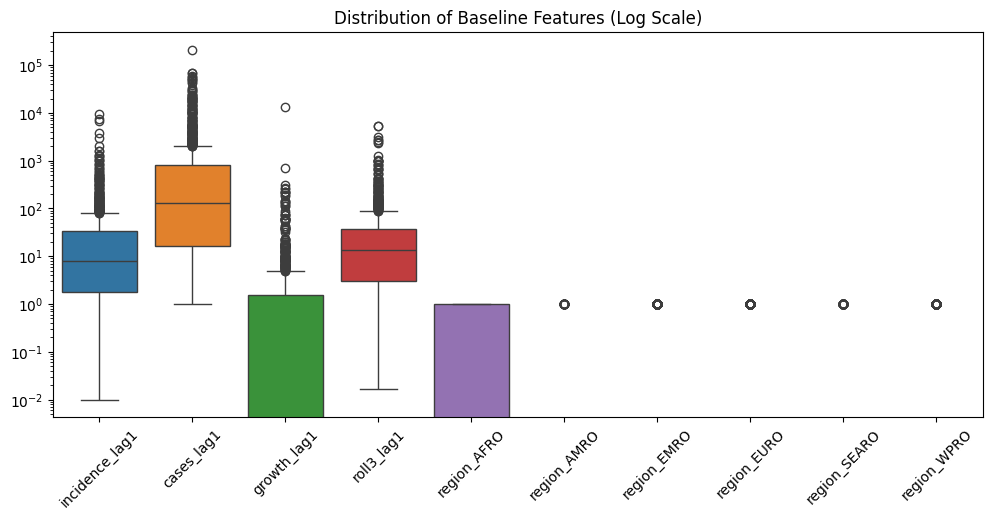

The wide range in values explains why SVM struggled. To fix this, SVM requires data scaling (Mean=0, Std=1).


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Visualize the massive difference in scales
plt.figure(figsize=(12, 5))
sns.boxplot(data=df_model[features_base])
plt.yscale('log')
plt.title("Distribution of Baseline Features (Log Scale)")
plt.xticks(rotation=45)
plt.show()

print("The wide range in values explains why SVM struggled. To fix this, SVM requires data scaling (Mean=0, Std=1).")

#### Re-evaluating SVM with Scaling

We can use a `Pipeline` to ensure that scaling is performed correctly within each fold of the cross-validation (preventing data leakage).

In [ ]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# Create a pipeline that scales data THEN applies SVM
scaled_svc_model = make_pipeline(StandardScaler(), SVC(probability=True, class_weight='balanced', random_state=42))

# Re-run cross-validation
scaled_scores = cross_val_score(
    scaled_svc_model,
    X_full,
    y_full,
    cv=outer_cv,
    scoring='roc_auc'
)

print(f"SVM with Scaling Mean ROC-AUC: {scaled_scores.mean():.4f}")
print(f"Previous SVM Mean ROC-AUC (from cell nB1T5tFB58_8): 0.6454")

SVM with Scaling Mean ROC-AUC: 0.6335
Previous SVM Mean ROC-AUC (from cell nB1T5tFB58_8): 0.6454


### Model Performance Comparison
Comparing the Mean ROC-AUC scores from the nested cross-validation for Logistic Regression, Random Forest, and SVM (Scaled).

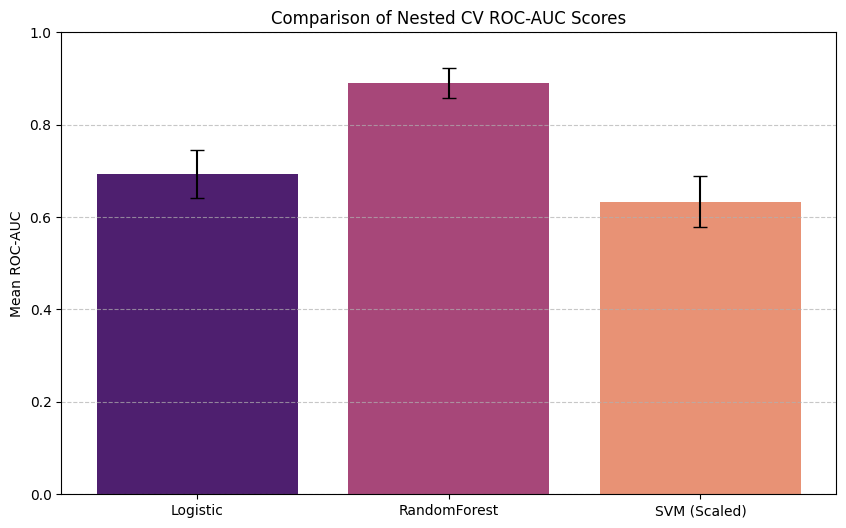

In [ ]:
model_names = ['Logistic', 'RandomForest', 'SVM (Scaled)']
scores = [nested_scores_lr.mean(), nested_scores_rf.mean(), scaled_scores.mean()]
std_devs = [nested_scores_lr.std(), nested_scores_rf.std(), scaled_scores.std()]

plt.figure(figsize=(10, 6))
sns.barplot(x=model_names, y=scores, palette='magma')
plt.errorbar(x=model_names, y=scores, yerr=std_devs, fmt='none', c='black', capsize=5)
plt.title('Comparison of Nested CV ROC-AUC Scores')
plt.ylabel('Mean ROC-AUC')
plt.ylim(0, 1.0)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

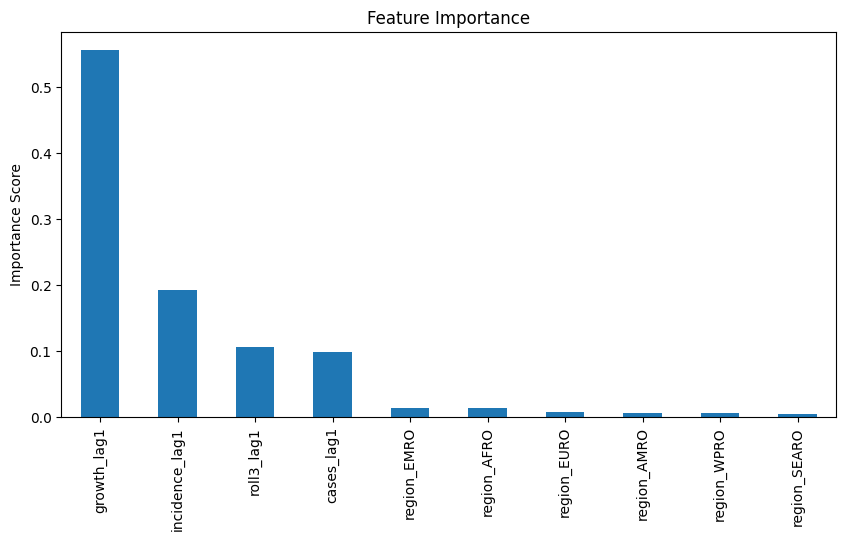

In [ ]:
rf = models["RandomForest"]

importances = pd.Series(
    rf.feature_importances_,
    index=features_base
).sort_values(ascending=False)

# Plot
importances.plot(kind="bar", figsize=(10,5), title="Feature Importance")
plt.ylabel("Importance Score")
plt.show()

### Adding more features


#### Model-1


In [ ]:
features_base = [
    "incidence_lag1",
    "cases_lag1",
    "growth_lag1",
    "roll3_lag1",
] + [c for c in df.columns if c.startswith("region_")]

#### Model-2

In [ ]:
df["lab_confirm_rate"] = df["measles_lab_confirmed"] / df["measles_total"]
df["discard_rate"] = df["discarded_cases"] / df["total_suspected_measles_rubella_cases"]
df["clinical_ratio"] = df["measles_clinical"] / df["measles_total"]
df["epi_ratio"] = df["measles_epi_linked"] / df["measles_total"]

df = df.replace([np.inf, -np.inf], np.nan)

features_enhanced = features_base + [
    "lab_confirm_rate",
    "discard_rate",
    "clinical_ratio",
    "epi_ratio"
]

#### Model-3

`Seasonal data`

In [ ]:
# Aggregate monthly data
monthly = cases_month.copy()

# 1. Capture the specific peak season effect (Oct, Nov, Dec, Jan, Feb, Mar)
# We define a peak season mask
peak_months = [10, 11, 12, 1, 2, 3]
monthly['is_peak_season'] = monthly['month'].isin(peak_months)

# Calculate seasonal intensity
seasonal_intensity = monthly.groupby(['country', 'year']).apply(
    lambda x: x[x['is_peak_season']]['measles_total'].sum()
).reset_index(name='peak_season_cases')

# 2. Standard monthly features
monthly_stats = monthly.groupby(["country", "year"]).agg(
    peak_cases=("measles_total", "max"),
    variability=("measles_total", "std"),
    outbreak_duration=("measles_total", lambda x: (x > 10).sum())
).reset_index()

# Merge and shift seasonal features by 1 year to prevent leakage
monthly_stats = monthly_stats.merge(seasonal_intensity, on=["country", "year"], how="left")
monthly_stats = monthly_stats.sort_values(["country", "year"])

monthly_stats["peak_cases"] = monthly_stats.groupby("country")["peak_cases"].shift(1)
monthly_stats["variability"] = monthly_stats.groupby("country")["variability"].shift(1)
monthly_stats["peak_season_lag1"] = monthly_stats.groupby("country")["peak_season_cases"].shift(1)

# Merge monthly features into the main dataframe
if 'outbreak_duration' in df.columns:
    df = df.drop(columns=['outbreak_duration', 'peak_cases', 'variability', 'peak_season_lag1'], errors='ignore')

df = df.merge(monthly_stats.drop(columns=['peak_season_cases']), on=["country", "year"], how="left")

# Feature engineering for discarded cases and outbreak lag
df["discarded_rate_per_pop"] = pd.to_numeric(
    df["discarded_non_measles_rubella_cases_per_100000_total_population"],
    errors="coerce"
)
df["discarded_rate_lag1"] = df.groupby("country")["discarded_rate_per_pop"].shift(1)
df["discarded_growth"] = df.groupby("country")["discarded_rate_per_pop"].pct_change().replace([np.inf, -np.inf], np.nan)

# Create the lag for outbreak duration
df["outbreak_duration_lag1"] = df.groupby("country")["outbreak_duration"].shift(1)
df["was_outbreak_lag1"] = df.groupby("country")["outbreak_iqr"].shift(1).astype(float)
# Define the advanced feature set with the new seasonal lag
features_advanced = features_enhanced + [
    "peak_cases",
    "variability",
    "outbreak_duration_lag1",
    "peak_season_lag1",
    "was_outbreak_lag1"
]

print("Features successfully engineered with seasonal peak lag (Oct-Mar).")
display(monthly)

Features successfully engineered with seasonal peak lag (Oct-Mar).


,region,country,iso3,year,month,measles_suspect,measles_clinical,measles_epi_linked,measles_lab_confirmed,measles_total,rubella_clinical,rubella_epi_linked,rubella_lab_confirmed,rubella_total,discarded,is_peak_season
0,AFR,Algeria,DZA,2012,1,8.0,6.0,0.0,2.0,8.0,NaN,NaN,NaN,NaN,0.0,True
1,AFR,Algeria,DZA,2012,2,10.0,10.0,0.0,0.0,10.0,NaN,NaN,NaN,NaN,0.0,True
2,AFR,Algeria,DZA,2012,3,17.0,17.0,0.0,0.0,17.0,NaN,NaN,NaN,NaN,0.0,True
3,AFR,Algeria,DZA,2012,4,7.0,5.0,0.0,0.0,5.0,0.0,0.0,1.0,1.0,2.0,False
4,AFR,Algeria,DZA,2012,5,14.0,11.0,0.0,0.0,11.0,0.0,0.0,3.0,3.0,3.0,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
22775,WPR,Viet Nam,VNM,2024,10,379.0,19.0,56.0,256.0,331.0,5.0,0.0,5.0,10.0,48.0,True
22776,WPR,Viet Nam,VNM,2024,11,584.0,37.0,125.0,347.0,509.0,0.0,0.0,1.0,1.0,75.0,True
22777,WPR,Viet Nam,VNM,2024,12,588.0,56.0,134.0,338.0,528.0,0.0,0.0,1.0,1.0,60.0,True
22778,WPR,Viet Nam,VNM,2025,1,156.0,7.0,0.0,124.0,131.0,NaN,NaN,NaN,NaN,25.0,True


In [ ]:
#unified features list
all_features = list(set(features_base + features_enhanced + features_advanced))

# Create a single evaluation dataset where all features are present
df_eval = df[all_features + ["outbreak_mean_std", "year", "country"]].dropna()

print(f"Total rows for unified evaluation: {len(df_eval)}")
print(f"Test rows (post-2022): {len(df_eval[df_eval['year'] > 2022])}")

# Re-train and evaluate on this identical data
def evaluate_on_same_set(df_eval, features, name):
    train = df_eval[df_eval["year"] <= 2022]
    test  = df_eval[df_eval["year"] > 2022]

    X_train, y_train = train[features], train["outbreak_mean_std"]
    X_test, y_test = test[features], test["outbreak_mean_std"]

    model = RandomForestClassifier(n_estimators=200, max_depth=6, class_weight='balanced', random_state=42)
    model.fit(X_train, y_train)

    probs = model.predict_proba(X_test)[:, 1]
    auc = roc_auc_score(y_test, probs)
    print(f"\n--- {name} ---")
    print(f"ROC-AUC: {auc:.4f}")
    print(classification_report(y_test, model.predict(X_test)))
    return model

model1 = evaluate_on_same_set(df_eval, features_base, "Baseline Model (Unified Set)")
model2 = evaluate_on_same_set(df_eval, features_enhanced, "Enhanced Model (Unified Set)")
model3 = evaluate_on_same_set(df_eval, features_advanced, "Advanced Model (Unified Set)")

Total rows for unified evaluation: 1189
Test rows (post-2022): 342

--- Baseline Model (Unified Set) ---
ROC-AUC: 0.8631
              precision    recall  f1-score   support

       False       0.92      0.84      0.88       273
        True       0.53      0.70      0.60        69

    accuracy                           0.81       342
   macro avg       0.72      0.77      0.74       342
weighted avg       0.84      0.81      0.82       342


--- Enhanced Model (Unified Set) ---
ROC-AUC: 0.8320
              precision    recall  f1-score   support

       False       0.88      0.85      0.86       273
        True       0.47      0.54      0.50        69

    accuracy                           0.78       342
   macro avg       0.67      0.69      0.68       342
weighted avg       0.80      0.78      0.79       342


--- Advanced Model (Unified Set) ---
ROC-AUC: 0.8472
              precision    recall  f1-score   support

       False       0.90      0.84      0.87       273
        

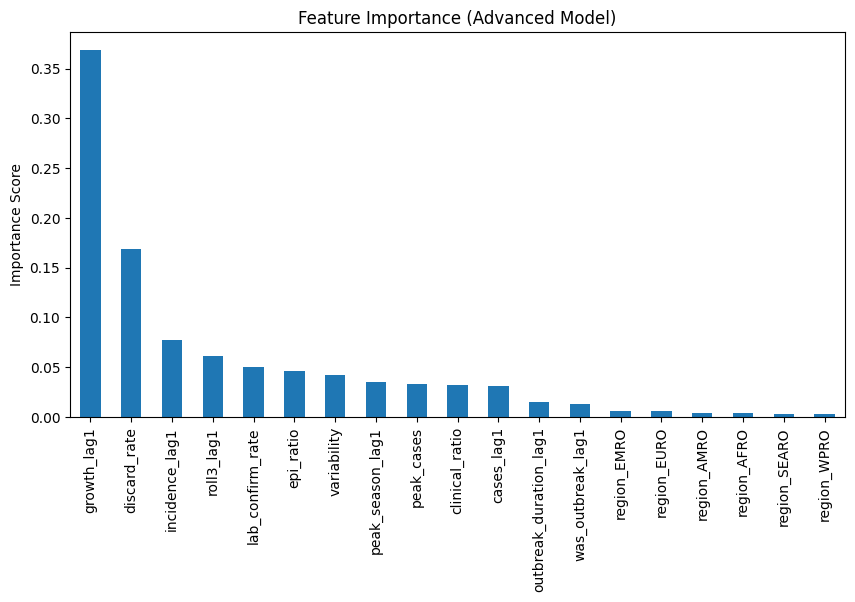

In [ ]:
rf_score = model3

importances = pd.Series(
    rf_score.feature_importances_,
    index=features_advanced
).sort_values(ascending=False)

# Plot
importances.plot(kind="bar", figsize=(10,5), title="Feature Importance (Advanced Model)")
plt.ylabel("Importance Score")
plt.show()

In [ ]:
def show_predictions(df_eval, features, model, name):
    test = df_eval[df_eval["year"] > 2022].copy()
    X_test = test[features]

    test["prob"] = model.predict_proba(X_test)[:, 1]
    test["predicted"] = model.predict(X_test)
    test["actual"] = test["outbreak_mean_std"]
    test["correct"] = test["predicted"] == test["actual"]

    print(f"\n=== {name} ===")
    display(
        test[["country", "year", "actual", "predicted", "prob", "correct"]]
        .sort_values("prob", ascending=False)
        .head(20)
    )

show_predictions(df_eval, features_base,model1, "Baseline Model")
show_predictions(df_eval, features_enhanced, model2, "Enhanced Model")
show_predictions(df_eval, features_advanced, model3, "Advanced Model")



=== Baseline Model ===


,country,year,actual,predicted,prob,correct
269,Bosnia and Herzegovina,2024,True,True,0.847103,True
1516,Netherlands (Kingdom of the),2025,False,True,0.785952,False
816,Georgia,2024,False,True,0.783589,False
1289,Malawi,2025,True,True,0.779985,True
843,Ghana,2023,True,True,0.767807,True
732,Ethiopia,2024,True,True,0.759881,True
2263,United Kingdom of Great Britain and Northern I...,2024,True,True,0.758089,True
1408,Mongolia,2025,False,True,0.757329,False
395,Canada,2025,True,True,0.748540,True
193,Belarus,2024,True,True,0.744290,True



=== Enhanced Model ===


,country,year,actual,predicted,prob,correct
732,Ethiopia,2024,True,True,0.822791,True
350,Burundi,2024,True,True,0.811433,True
382,Cameroon,2023,True,True,0.808955,True
787,Gabon,2023,True,True,0.772019,True
1516,Netherlands (Kingdom of the),2025,False,True,0.768078,False
395,Canada,2025,True,True,0.763327,True
1289,Malawi,2025,True,True,0.757610,True
731,Ethiopia,2023,False,True,0.751562,False
2236,Ukraine,2025,False,True,0.732074,False
844,Ghana,2024,True,True,0.727001,True



=== Advanced Model ===


,country,year,actual,predicted,prob,correct
732,Ethiopia,2024,True,True,0.784470,True
1289,Malawi,2025,True,True,0.779125,True
382,Cameroon,2023,True,True,0.771395,True
350,Burundi,2024,True,True,0.757139,True
1408,Mongolia,2025,False,True,0.742478,False
1516,Netherlands (Kingdom of the),2025,False,True,0.736520,False
816,Georgia,2024,False,True,0.736372,False
407,Central African Republic,2023,False,True,0.733418,False
1889,Serbia,2024,False,True,0.733192,False
395,Canada,2025,True,True,0.724071,True


### Hyperparameter Tuning with Cross-Validation

In [ ]:
from sklearn.model_selection import GridSearchCV

# Prepare the data for cross-validation using the advanced features
df_cv = df_eval[df_eval["year"] <= 2022].copy() # Use the same training data as before
X_cv, y_cv = df_cv[all_features], df_cv["outbreak_mean_std"]

# Define the parameter grid to search
param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [5, 10, 15, None],
    'min_samples_leaf': [1, 2, 4],
    'class_weight': ['balanced']
}

# Initialize the Random Forest Classifier
rf_model = RandomForestClassifier(random_state=42)

# Initialize GridSearchCV
# Using 'roc_auc' as the scoring metric since it's used in evaluation
grid_search = GridSearchCV(
    estimator=rf_model,
    param_grid=param_grid,
    scoring='roc_auc',
    cv=KFold(n_splits=5, shuffle=True, random_state=42),
    n_jobs=-1,
    verbose=1
)

# Fit GridSearchCV to the data
grid_search.fit(X_cv, y_cv)

print("Best parameters found: ", grid_search.best_params_)
print("Best ROC-AUC score: ", grid_search.best_score_)

Fitting 5 folds for each of 36 candidates, totalling 180 fits
Best parameters found:  {'class_weight': 'balanced', 'max_depth': 15, 'min_samples_leaf': 1, 'n_estimators': 200}
Best ROC-AUC score:  0.8970174763919662


### Inspecting Model Hyperparameters

There are two ways to look at hyperparameters: checking the default/current configuration of a model, or checking the 'best' parameters found during a grid search.

In [ ]:
# 1. Check all parameters of an existing model
print("Current Parameters for model1:")
display(model1.get_params())

# 2. Check the best parameters found during the Grid Search
# Note: This only works if grid_search.fit() has been successfully executed
try:
    print("\nBest Parameters found by GridSearchCV:")
    display(grid_search.best_params_)
except AttributeError:
    print("\nGrid search has not been fitted yet or failed.")

Current Parameters for model1:


{'bootstrap': True,
 'ccp_alpha': 0.0,
 'class_weight': 'balanced',
 'criterion': 'gini',
 'max_depth': 6,
 'max_features': 'sqrt',
 'max_leaf_nodes': None,
 'max_samples': None,
 'min_impurity_decrease': 0.0,
 'min_samples_leaf': 1,
 'min_samples_split': 2,
 'min_weight_fraction_leaf': 0.0,
 'monotonic_cst': None,
 'n_estimators': 200,
 'n_jobs': None,
 'oob_score': False,
 'random_state': 42,
 'verbose': 0,
 'warm_start': False}


Best Parameters found by GridSearchCV:


{'class_weight': 'balanced',
 'max_depth': 15,
 'min_samples_leaf': 1,
 'n_estimators': 200}

After finding the best parameters, you can retrain your model with these optimal settings and re-evaluate its performance on the test set.

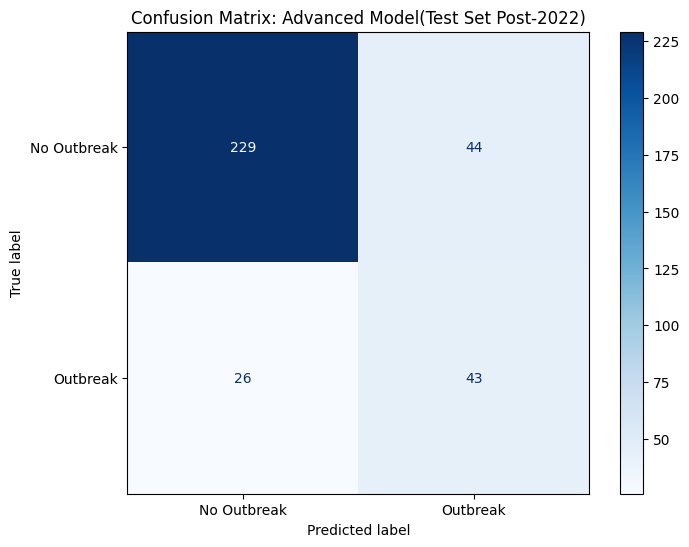

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Prepare test data for the Advanced Model
test_eval = df_eval[df_eval['year'] > 2022].copy()
X_test_eval = test_eval[features_advanced]
y_true = test_eval['outbreak_mean_std']

# Get predictions from the Advanced Model
y_pred = model3.predict(X_test_eval)

# Compute confusion matrix
cm = confusion_matrix(y_true, y_pred)

# Plot
fig, ax = plt.subplots(figsize=(8, 6))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['No Outbreak', 'Outbreak'])
disp.plot(cmap='Blues', ax=ax)
plt.title('Confusion Matrix: Advanced Model(Test Set Post-2022)')
plt.show()

In [ ]:
from sklearn.metrics import accuracy_score

# Retrieve best parameters from the grid search
best_params = grid_search.best_params_

# Initialize the final model with best params
final_rf_model = RandomForestClassifier(**best_params, random_state=42)

# Re-split data to match the evaluation used in grid_search (df_eval)
train_final = df_eval[df_eval['year'] <= 2022]
test_final = df_eval[df_eval['year'] > 2022]

X_train_final = train_final[features_base]
y_train_final = train_final['outbreak_mean_std']
X_test_final = test_final[features_base]
y_test_final = test_final['outbreak_mean_std']

# Train final model
final_rf_model.fit(X_train_final, y_train_final)

# Predict
y_train_pred = final_rf_model.predict(X_train_final)
y_test_pred = final_rf_model.predict(X_test_final)

# Calculate Accuracy
train_accuracy = accuracy_score(y_train_final, y_train_pred)
test_accuracy = accuracy_score(y_test_final, y_test_pred)

print(f"Tuned Random Forest Performance:")
print(f"- Training Accuracy: {train_accuracy:.4f}")
print(f"- Test Accuracy:     {test_accuracy:.4f}")

# Detailed report for test set
print("\nTest Set Classification Report:")
print(classification_report(y_test_final, y_test_pred))

Tuned Random Forest Performance:
- Training Accuracy: 0.9528
- Test Accuracy:     0.8392

Test Set Classification Report:
              precision    recall  f1-score   support

       False       0.91      0.89      0.90       273
        True       0.59      0.64      0.62        69

    accuracy                           0.84       342
   macro avg       0.75      0.76      0.76       342
weighted avg       0.84      0.84      0.84       342

